# Breathing Bharat: What 414,255 Hours of North Indian Air Tell Us
### VIZ-A-THON 2026 · Air Quality in North India · End-to-end data science notebook

**Dataset:** CPCB CAAQM stations — 48 stations across Chandigarh, Punjab, Haryana and Delhi.

| File | Rows | Columns | Grain |
|---|---:|---:|---|
| `air_quality_hourly_2025.csv` | 414,255 | 28 | station × hour (UTC) |
| `aqi_history_2017_2023.csv` | 102,744 | 29 | station × day (24 hourly AQI columns) |
| `stations.csv` | 48 | 4 | one monitoring station |

This notebook does five things, in order:

1. **Audits** the raw data — rows, columns, missingness, duplicates, unit and identity inconsistencies.
2. **Cleans and preprocesses** it with an explicit, defensible reason for every choice (and for the alternative we rejected).
3. **Analyses** the data — seasonality, diurnal cycles, wind, rain, long-term trend, exposure inequality, transport signatures.
4. **Forecasts** next-day PM2.5 and AQI risk with an honest time-based backtest, reporting accuracy against strong baselines.
5. **Exports a fresh, model-ready dataset** and proposes one unique problem statement + an innovative, deployable solution.

> **Headline:** the data is not a clean table. 43.6% of station-hours have **no pollutant reading at all**, one station ID in the history file is shared by **40 different physical stations across India**, and Haryana's PM2.5 coverage collapses to ~5% in summer. Cleaning is therefore not cosmetic — it changes every conclusion.

## Contents
1. [Setup & helpers](#1-setup--helpers)
2. [First look: shape, schema, missingness](#2-first-look)
3. [Data-quality audit: the six problems](#3-data-quality-audit)
4. [Preprocessing: what we did and why (not the alternative)](#4-preprocessing)
5. [Clean hourly + daily AQI dataset](#5-clean-dataset)
6. [Exploratory analysis: hidden patterns, trends, figures](#6-eda)
7. [Forecasting: accuracy against baselines](#7-forecasting)
8. [Fresh datasets exported](#8-fresh-datasets)
9. [Unique problem statement + proposed solution](#9-problem-statement)
10. [Real-world impact, pilot plan, limitations](#10-impact)

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
import re, difflib, warnings, json, os
from pathlib import Path
from math import radians, sin, cos, asin, sqrt
from scipy.optimize import minimize
from IPython.display import display, Markdown
from sklearn.metrics import (r2_score, mean_absolute_error, mean_squared_error,
                             accuracy_score, f1_score, recall_score,
                             classification_report, confusion_matrix)
from sklearn.utils.class_weight import compute_sample_weight
import lightgbm as lgb

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 170, "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.labelsize": 10, "legend.fontsize": 9,
})

BASE = Path(".")
RAW  = BASE / "data_raw" / "VIZ-A-THON_2026_Dataset"
PROC = BASE / "data_processed"
FIG  = BASE / "figures"
for p in (PROC, FIG):
    p.mkdir(parents=True, exist_ok=True)

STATE_COLORS = {"Delhi": "#c0392b", "Haryana": "#e67e22",
                "Punjab": "#2471a3", "Chandigarh": "#1e8449"}
CAT_ORDER = ["Good", "Satisfactory", "Moderate", "Poor", "Very Poor", "Severe"]
CAT_COLORS = {"Good": "#2ecc71", "Satisfactory": "#a3d977", "Moderate": "#f1c40f",
              "Poor": "#e67e22", "Very Poor": "#c0392b", "Severe": "#6c1b1b"}
TIER_ORDER = ["Low", "Moderate", "High"]

def savefig(fig, name):
    path = FIG / name
    fig.savefig(path, bbox_inches="tight", facecolor="white")
    return path

# ---------- CPCB AQI breakpoints (concentration -> sub-index) ----------
BREAKPOINTS = {
    "pm25": ([0, 30, 60, 90, 120, 250, 500], [0, 50, 100, 200, 300, 400, 500]),
    "pm10": ([0, 50, 100, 250, 350, 430, 600], [0, 50, 100, 200, 300, 400, 500]),
    "no2":  ([0, 40, 80, 180, 280, 400, 600], [0, 50, 100, 200, 300, 400, 500]),
    "o3":   ([0, 50, 100, 168, 208, 748, 1000], [0, 50, 100, 200, 300, 400, 500]),
    "co":   ([0, 1, 2, 10, 17, 34, 50], [0, 50, 100, 200, 300, 400, 500]),
    "so2":  ([0, 40, 80, 380, 800, 1600, 2000], [0, 50, 100, 200, 300, 400, 500]),
    "nh3":  ([0, 200, 400, 800, 1200, 1800, 2400], [0, 50, 100, 200, 300, 400, 500]),
}

def subindex(x, pol):
    if pd.isna(x):
        return np.nan
    b, a = BREAKPOINTS[pol]
    if x <= b[0]:
        return 0.0
    if x >= b[-1]:
        return 500.0
    return float(np.interp(x, b, a))

def aqi_category(a):
    if pd.isna(a): return np.nan
    if a <= 50: return "Good"
    if a <= 100: return "Satisfactory"
    if a <= 200: return "Moderate"
    if a <= 300: return "Poor"
    if a <= 400: return "Very Poor"
    return "Severe"

def tier_of(a):
    if pd.isna(a): return np.nan
    if a <= 100: return "Low"
    if a <= 200: return "Moderate"
    return "High"

def aqi_to_pm25(a):
    if pd.isna(a): return np.nan
    return float(np.interp(a, BREAKPOINTS["pm25"][1], BREAKPOINTS["pm25"][0]))

def norm_name(x):
    x = str(x).lower()
    x = re.sub(r"[^a-z0-9 ]", " ", x)
    x = re.sub(r"\b(hspcb|dppc|ppcb|imd|iitm|cpcc|rspcb|uppcb|mppcb|kspcb|ipca|lab|spcb|pcb|tnpcb|ukpcb|mpcb|bspcb|jspcb|cecb|ppcc)\b", " ", x)
    return re.sub(r"\s+", " ", x).strip()

def haversine(lat1, lon1, lat2, lon2):
    R = 6371.0
    dlat, dlon = radians(lat2 - lat1), radians(lon2 - lon1)
    a = sin(dlat / 2) ** 2 + cos(radians(lat1)) * cos(radians(lat2)) * sin(dlon / 2) ** 2
    return 2 * R * asin(sqrt(a))

def bearing(lat1, lon1, lat2, lon2):
    y = sin(radians(lon2 - lon1)) * cos(radians(lat2))
    x = cos(radians(lat1)) * sin(radians(lat2)) - sin(radians(lat1)) * cos(radians(lat2)) * cos(radians(lon2 - lon1))
    return (np.degrees(np.arctan2(y, x)) + 360) % 360

def season_of_month(m):
    if m in (12, 1, 2): return "Winter"
    if m in (3, 4, 5): return "Pre-monsoon"
    if m in (6, 7, 8, 9): return "Monsoon"
    return "Post-monsoon"

def reg_metrics(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    m = ~(np.isnan(y) | np.isnan(p))
    y, p = y[m], p[m]
    return {"R2": r2_score(y, p), "MAE": mean_absolute_error(y, p),
            "RMSE": mean_squared_error(y, p) ** 0.5,
            "Bias": float(np.mean(p - y)), "n": int(m.sum())}

print("Environment ready · pandas", pd.__version__, "· LightGBM", lgb.__version__)

Environment ready · pandas 2.2.2 · LightGBM 4.7.0


<a id="2-first-look"></a>
## 2. First look: shape, schema, missingness

We load the three files exactly as published. Column names contain mojibake (`Âµg/mÂ³`) and units are embedded in the header, so we rename them **by position** to stable snake_case names. Renaming by position is safer than string matching here: the encoding of `µ` differs between readers and would silently break a name-based rename.

In [2]:
hourly_raw = pd.read_csv(RAW / "air_quality_hourly_2025.csv", low_memory=False)
stations   = pd.read_csv(RAW / "stations.csv")
hist_raw   = pd.read_csv(RAW / "aqi_history_2017_2023.csv", low_memory=False)

COLS = ["station_id","state","city","station_name","timestamp_utc",
        "pm25","pm10","no","no2","nox_ppb","nh3","so2","co","o3",
        "benzene","toluene","xylene","ethylbenzene","mp_xylene",
        "temp_c","rh_pct","ws_ms","wd_deg","rain_mm","total_rain_mm",
        "solar_wm2","pressure_mmhg","vws_ms"]
hourly_raw.columns = COLS
stations.columns = ["state","station_id","city","station_name"]
hist_raw = hist_raw.rename(columns={"Station ID":"station_id","State":"state",
                                    "City":"city","Station Name":"station_name","Date":"date"})

hourly_raw["timestamp_utc"] = pd.to_datetime(hourly_raw["timestamp_utc"])
hourly_raw["timestamp_ist"] = hourly_raw["timestamp_utc"] + pd.Timedelta(hours=5, minutes=30)
hourly_raw["date_ist"] = hourly_raw["timestamp_ist"].dt.normalize()
hourly_raw["month"] = hourly_raw["timestamp_ist"].dt.month
hist_raw["date"] = pd.to_datetime(hist_raw["date"], errors="coerce")

summary = pd.DataFrame({
    "file": ["air_quality_hourly_2025.csv", "aqi_history_2017_2023.csv", "stations.csv"],
    "rows": [len(hourly_raw), len(hist_raw), len(stations)],
    "columns": [hourly_raw.shape[1] - 4, hist_raw.shape[1] - 5, stations.shape[1]],
    "grain": ["station × hour (UTC)", "station × day", "station"],
})
display(summary)
print("Hourly memory:", round(hourly_raw.memory_usage(deep=True).sum()/1e6, 1), "MB")
display(hourly_raw.head(3)[["station_id","state","city","timestamp_utc","timestamp_ist","pm25","pm10","no2","co","o3","ws_ms","wd_deg"]])

,file,rows,columns,grain
0,air_quality_hourly_2025.csv,414255,27,station × hour (UTC)
1,aqi_history_2017_2023.csv,102744,24,station × day
2,stations.csv,48,4,station


Hourly memory: 191.1 MB


,station_id,state,city,timestamp_utc,timestamp_ist,pm25,pm10,no2,co,o3,ws_ms,wd_deg
0,site_5491,Chandigarh,Chandigarh,2025-01-01 00:00:00,2025-01-01 05:30:00,152.0,216.0,35.7,1.01,13.5,0.4,13.0
1,site_5491,Chandigarh,Chandigarh,2025-01-01 01:00:00,2025-01-01 06:30:00,154.0,242.0,41.4,0.96,NaN,0.4,74.0
2,site_5491,Chandigarh,Chandigarh,2025-01-01 02:00:00,2025-01-01 07:30:00,140.0,219.0,NaN,NaN,21.7,0.4,350.0


**What the first rows show.** Timestamps are UTC; the `Timestamp` 00:00 becomes 05:30 IST. Pollutant columns are sparse: the first three rows already contain a fully blank pollutant block. Units are mixed — `NOx` is in **ppb** while `NO`, `NO2`, `NH3`, `SO2` and particulates are in **µg/m³**, and `CO` is in **mg/m³**.

In [3]:
miss = pd.DataFrame({
    "missing": hourly_raw.isna().sum(),
    "pct": (hourly_raw.isna().mean() * 100).round(1),
}).sort_values("pct", ascending=False)
print("Missing values — top 22 columns")
display(miss.head(22))

pol = ["pm25","pm10","no","no2","nox_ppb","nh3","so2","co","o3"]
n_all_missing = hourly_raw[pol].isna().all(axis=1).sum()
n_pm_missing  = (hourly_raw.pm25.isna() & hourly_raw.pm10.isna()).sum()
print(f"Rows with ALL nine pollutant readings missing : {n_all_missing:,} ({100*n_all_missing/len(hourly_raw):.1f}%)")
print(f"Rows with BOTH PM2.5 and PM10 missing        : {n_pm_missing:,} ({100*n_pm_missing/len(hourly_raw):.1f}%)")
print(f"Rows with PM2.5 present                      : {hourly_raw.pm25.notna().sum():,} ({100*hourly_raw.pm25.notna().mean():.1f}%)")
print(f"Duplicate (station_id, timestamp_utc) pairs  : {hourly_raw.duplicated(['station_id','timestamp_utc']).sum():,}")

Missing values — top 22 columns


,missing,pct
vws_ms,407220,98.3
xylene,355132,85.7
pressure_mmhg,336968,81.3
temp_c,295005,71.2
ethylbenzene,293973,71.0
mp_xylene,293299,70.8
solar_wm2,243503,58.8
rh_pct,234211,56.5
rain_mm,233377,56.3
nh3,228389,55.1


Rows with ALL nine pollutant readings missing : 180,556 (43.6%)
Rows with BOTH PM2.5 and PM10 missing        : 192,294 (46.4%)
Rows with PM2.5 present                      : 218,917 (52.8%)


Duplicate (station_id, timestamp_utc) pairs  : 0


Best-covered stations


,station_id,state,raw_rows,pm25_valid,pm25_cov_pct
2,site_1426,Delhi,8760,8628,98.493151
14,site_253,Punjab,8604,8470,98.442585
3,site_1429,Delhi,8760,8617,98.367580
1,site_1422,Delhi,8760,8569,97.819635
4,site_1431,Delhi,8760,8552,97.625571
5,site_1434,Delhi,8760,8543,97.522831
0,site_1420,Delhi,8760,8540,97.488584
16,site_256,Punjab,8494,8216,96.727101


Worst-covered stations


,station_id,state,raw_rows,pm25_valid,pm25_cov_pct
17,site_263,Haryana,8760,0,0.000000
24,site_5046,Haryana,8760,1311,14.965753
35,site_5057,Haryana,8760,1446,16.506849
20,site_5041,Haryana,8760,1660,18.949772
26,site_5048,Haryana,8760,1727,19.714612
19,site_5039,Haryana,8760,1814,20.707763
32,site_5054,Haryana,8760,1902,21.712329
22,site_5044,Haryana,8760,1941,22.157534
25,site_5047,Haryana,8760,1946,22.214612
37,site_5072,Haryana,8760,1957,22.340183


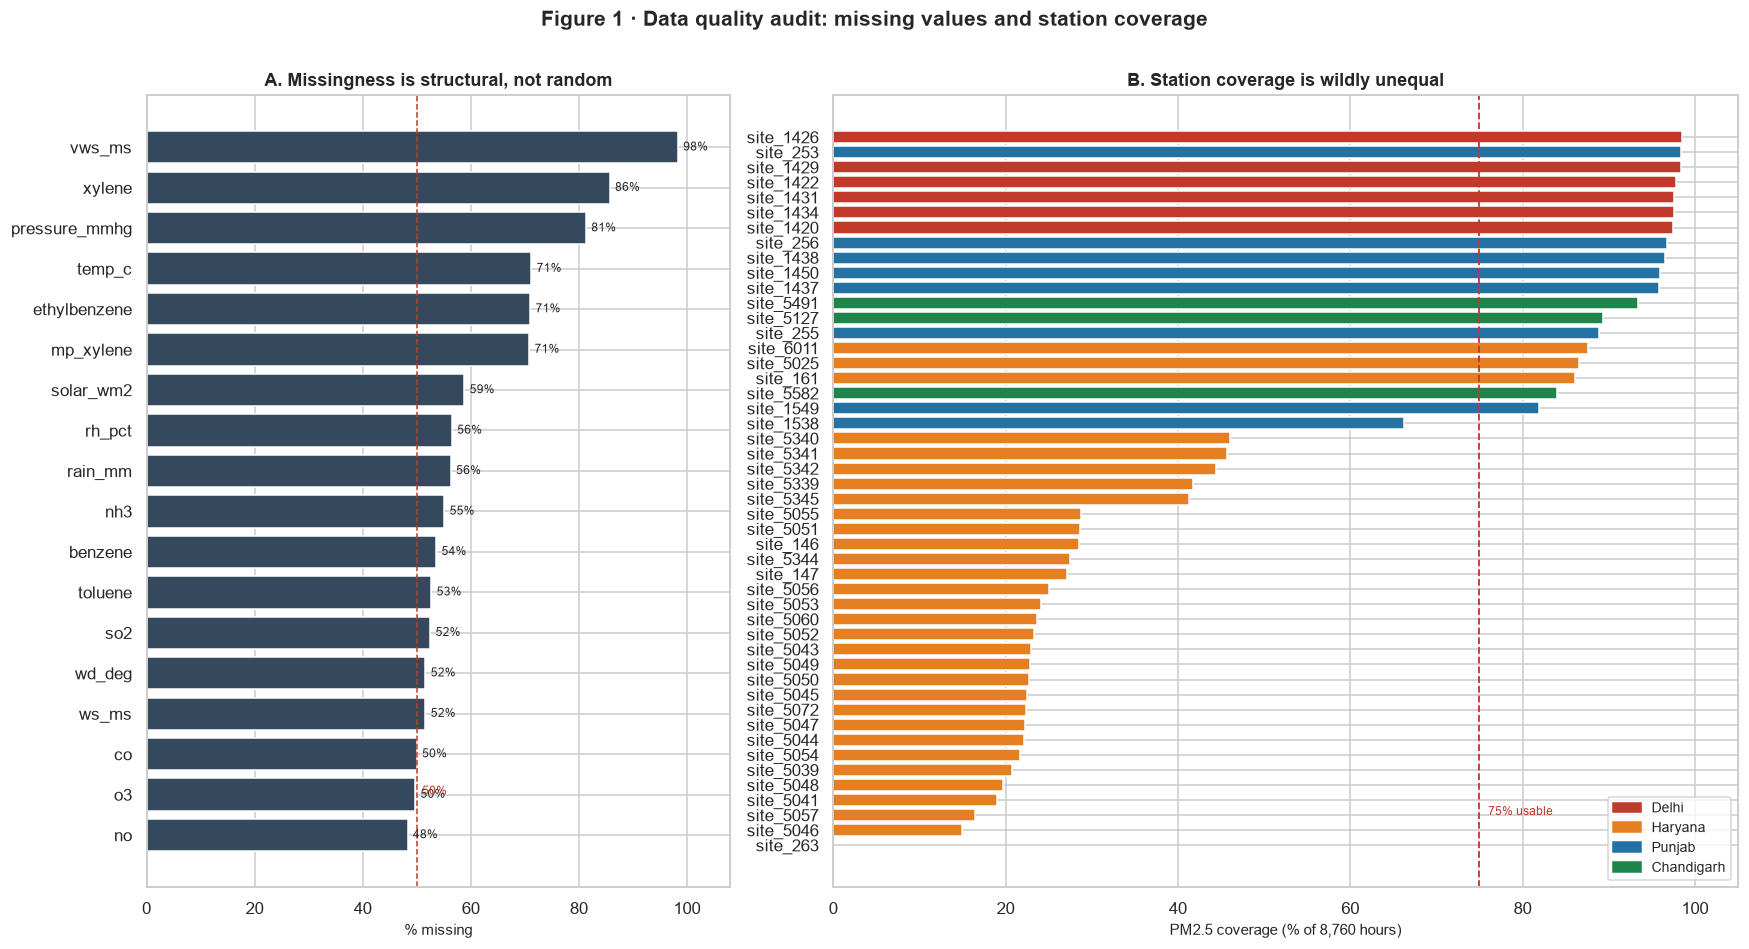

Coverage summary by state


,count,min,median,max
state,,,,
Chandigarh,3,83.9,89.3,93.4
Delhi,6,97.5,97.7,98.5
Haryana,31,0.0,23.7,87.6
Punjab,8,66.2,95.9,98.4


In [4]:
cov = (hourly_raw.groupby(["station_id","state"], as_index=False)
       .agg(raw_rows=("pm25","size"), pm25_valid=("pm25","count")))
cov["pm25_cov_pct"] = 100 * cov.pm25_valid / cov.raw_rows
cov = cov.sort_values("pm25_cov_pct")

print("Best-covered stations")
display(cov.tail(8).sort_values("pm25_cov_pct", ascending=False))
print("Worst-covered stations")
display(cov.head(12))

fig, axes = plt.subplots(1, 2, figsize=(16, 8.5), gridspec_kw={"width_ratios":[1, 1.55]})
top = miss.head(18).sort_values("pct")
axes[0].barh(top.index, top.pct, color="#34495e")
for i, v in enumerate(top.pct):
    axes[0].text(v + 1, i, f"{v:.0f}%", va="center", fontsize=8)
axes[0].set_xlim(0, 108)
axes[0].set_xlabel("% missing")
axes[0].set_title("A. Missingness is structural, not random")
axes[0].axvline(50, color="#c0392b", ls="--", lw=1)
axes[0].text(51, 1, "50%", color="#c0392b", fontsize=8)

colors = [STATE_COLORS[s] for s in cov.state]
axes[1].barh(cov.station_id, cov.pm25_cov_pct, color=colors)
axes[1].axvline(75, color="#c0392b", ls="--", lw=1.2)
axes[1].text(76, 2, "75% usable", color="#c0392b", fontsize=8)
axes[1].set_xlim(0, 105)
axes[1].set_xlabel("PM2.5 coverage (% of 8,760 hours)")
axes[1].set_title("B. Station coverage is wildly unequal")
from matplotlib.patches import Patch
axes[1].legend(handles=[Patch(color=c, label=s) for s, c in STATE_COLORS.items()],
               loc="lower right", frameon=True)
fig.suptitle("Figure 1 · Data quality audit: missing values and station coverage", fontsize=14, fontweight="bold", y=1.01)
fig.tight_layout()
savefig(fig, "fig01_missingness_coverage.png")
plt.show()
print("Coverage summary by state")
display(cov.groupby("state").pm25_cov_pct.agg(["count","min","median","max"]).round(1))

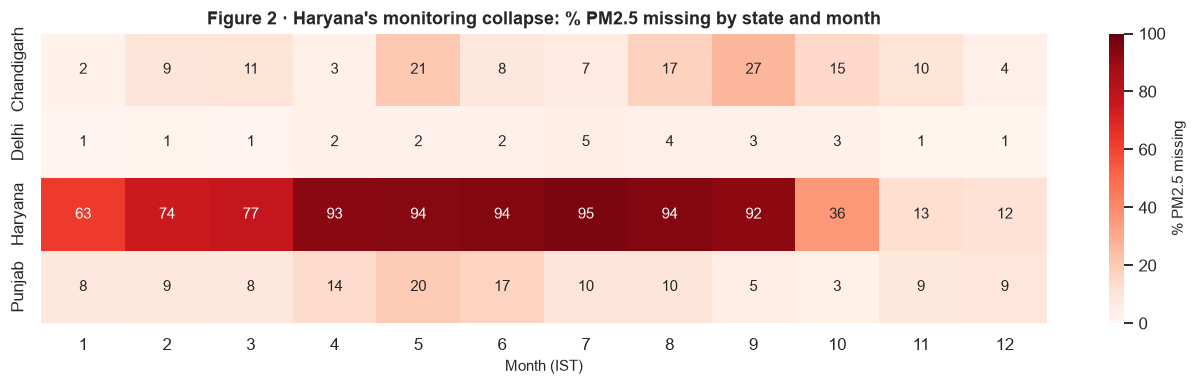

Haryana missing PM2.5 by month (%):


month,1,2,3,4,5,6,7,8,9,10,11,12
missing_pct,62.7,74.5,77.2,92.8,93.7,94.3,95.4,94.2,92.2,36.1,13.1,11.6


In [5]:
monthly_cov = (hourly_raw.assign(month=hourly_raw.timestamp_ist.dt.month)
               .groupby(["state","month"])
               .pm25.apply(lambda x: 100 * x.isna().mean())
               .unstack())
fig, ax = plt.subplots(figsize=(12, 3.6))
sns.heatmap(monthly_cov, annot=True, fmt=".0f", cmap="Reds", vmin=0, vmax=100,
            cbar_kws={"label": "% PM2.5 missing"}, ax=ax)
ax.set_title("Figure 2 · Haryana's monitoring collapse: % PM2.5 missing by state and month")
ax.set_xlabel("Month (IST)"); ax.set_ylabel("")
fig.tight_layout(); savefig(fig, "fig02_missingness_heatmap.png"); plt.show()
print("Haryana missing PM2.5 by month (%):")
display(monthly_cov.loc["Haryana"].round(1).to_frame("missing_pct").T)

**Finding 1 — missingness is the story, not a nuisance.** 43.6% of all station-hours have no pollutant reading. Haryana's PM2.5 coverage is ~5% in July–September but ~87% in November–December. Any state comparison that ignores this will be biased: summer Haryana looks "clean" simply because it is mostly unobserved. We therefore (a) never impute long gaps, (b) require a minimum number of valid hours for daily aggregates, and (c) label low-coverage stations in every export.

<a id="3-data-quality-audit"></a>
## 3. Data-quality audit: the six problems

We checked six classes of defects. Each is shown with evidence, because the preprocessing choices in §4 follow directly from them.

In [6]:
print("1) DUPLICATES")
print("   hourly station+timestamp duplicates:", hourly_raw.duplicated(["station_id","timestamp_utc"]).sum())
print("   history full-row duplicates        :", hist_raw.duplicated().sum())
print("   history station+date duplicates    :", hist_raw.duplicated(["station_id","date"]).sum())

print("\n2) TIMESTAMP / TIMEZONE")
print("   first UTC timestamp :", hourly_raw.timestamp_utc.min())
print("   first IST timestamp :", hourly_raw.timestamp_ist.min())
print("   non-zero minutes    :", (hourly_raw.timestamp_utc.dt.minute != 0).sum())
print("   non-zero seconds    :", (hourly_raw.timestamp_utc.dt.second != 0).sum())

print("\n3) UNIT INCONSISTENCY")
print("   NOx column is ppb, NO/NO2 are ug/m3. NOx vs (NO/30 + NO2/46)*46 correlation:")
sub = hourly_raw.dropna(subset=["no","no2","nox_ppb"]).copy()
sub["nox_calc"] = (sub.no/30 + sub.no2/46) * 46
print("   corr(NOx_ppb*1.88, NO+NO2 as NO2) =", round(np.corrcoef(sub.nox_ppb*1.88, sub.nox_calc)[0,1], 4))

print("\n4) DUPLICATE / NEAR-EMPTY COLUMNS")
print("   max |RF - TOT-RF| =", (hourly_raw.rain_mm - hourly_raw.total_rain_mm).abs().max())
print("   VWS missing       =", f"{100*hourly_raw.vws_ms.isna().mean():.1f}%")
print("   Xylene missing    =", f"{100*hourly_raw.xylene.isna().mean():.1f}%")
print("   BP missing        =", f"{100*hourly_raw.pressure_mmhg.isna().mean():.1f}%")

print("\n5) INSTRUMENT CEILINGS / SENTINELS")
for c, vals in [("pm25",[999.99,500]), ("pm10",[1000,999.99]),
                ("co",[10.0,4.0]), ("nox_ppb",[499.4]), ("no2",[497.13])]:
    print(f"   {c:8s}", {v: int((hourly_raw[c] == v).sum()) for v in vals})
print("   negative values in pollutants:", int((hourly_raw[pol] < 0).sum().sum()))

print("\n6) STATION IDENTITY IN THE HISTORY FILE")
g = hist_raw.groupby("station_id").agg(rows=("date","size"), dates=("date","nunique"),
                                       names=("station_name","nunique"))
display(g.sort_values("names", ascending=False).head(6))
print("distinct (station_id, station_name) pairs:", hist_raw[["station_id","station_name"]].drop_duplicates().shape[0])

1) DUPLICATES


   hourly station+timestamp duplicates:

 0


   history full-row duplicates        : 0
   history station+date duplicates    : 42257

2) TIMESTAMP / TIMEZONE
   first UTC timestamp : 2025-01-01 00:00:00
   first IST timestamp : 2025-01-01 05:30:00
   non-zero minutes    : 0
   non-zero seconds    : 0

3) UNIT INCONSISTENCY
   NOx column is ppb, NO/NO2 are ug/m3. NOx vs (NO/30 + NO2/46)*46 correlation:


   corr(NOx_ppb*1.88, NO+NO2 as NO2) = 0.9756

4) DUPLICATE / NEAR-EMPTY COLUMNS
   max |RF - TOT-RF| = 0.0
   VWS missing       = 98.3%
   Xylene missing    = 85.7%
   BP missing        = 81.3%

5) INSTRUMENT CEILINGS / SENTINELS
   pm25     {999.99: 11, 500: 7}
   pm10     {1000: 1, 999.99: 1}
   co       {10.0: 10, 4.0: 28}
   nox_ppb  {499.4: 1}
   no2      {497.13: 1}
   negative values in pollutants: 0

6) STATION IDENTITY IN THE HISTORY FILE


,rows,dates,names
station_id,,,
site_5046,35066,2279,40
site_5344,6767,2453,4
site_5341,6080,2459,4
site_5582,3142,1607,3
site_147,2227,2227,1
site_1438,2153,2153,1


distinct (station_id, station_name) pairs: 78


**Finding 2 — the history file's `Station ID` is not a key.** Four IDs are reused across multiple physical stations. `site_5046`, labelled *Gobind Pura, Yamuna Nagar* in `stations.csv`, carries **40 different station names** from Kanpur, Jaipur, Bhopal, Ghaziabad, Ratlam and elsewhere. `site_5344`, `site_5341` and `site_5582` similarly pool 4, 4 and 3 stations. The result is 42,257 duplicate station-date rows. Joining on `Station ID` alone would attach the wrong city's AQI to a station — a silent, analysis-destroying error.

The fix is a **composite identity**: normalise the station name (strip agency suffixes, punctuation, case), exact-match it to `stations.csv`, and **reject ambiguous names**. Exact matching is deliberately conservative: the score gap between true matches and the next candidate is large, and a wrong match is worse than a missing one.

In [7]:
stations["norm"] = stations.station_name.map(norm_name)
hist_raw["norm"] = hist_raw.station_name.map(norm_name)
lookup = dict(zip(stations.norm, stations.station_id))
hist_raw["station_id_fix"] = hist_raw.norm.map(lookup)

mapped_rows = hist_raw.station_id_fix.notna().sum()
print(f"History rows mapped exactly : {mapped_rows:,} / {len(hist_raw):,} ({100*mapped_rows/len(hist_raw):.1f}%)")
print(f"Physical stations recovered : {hist_raw.station_id_fix.nunique()} (raw IDs: {hist_raw.station_id.nunique()})")

# show what the exact-match rule rejects
unmatched = (hist_raw[hist_raw.station_id_fix.isna()]
             .groupby("station_name").size().sort_values(ascending=False).head(8))
print("\nLargest rejected name groups (correctly not in our 48 stations):")
display(unmatched.to_frame("rows"))

hist_mapped = hist_raw.dropna(subset=["station_id_fix"]).copy()
hist_mapped["station_id"] = hist_mapped["station_id_fix"]
hist_mapped = hist_mapped.drop(columns=["station_id_fix"])
print("After identity repair, duplicate station+date rows:", hist_mapped.duplicated(["station_id","date"]).sum())

# show the repaired collisions explicitly
fix_view = (hist_mapped[hist_mapped.station_id.isin(["site_5046","site_5344","site_5341","site_5582"])]
            .groupby(["station_id","station_name"]).size().reset_index(name="rows"))
display(fix_view.head(12))

History rows mapped exactly : 71,294 / 102,744 (69.4%)
Physical stations recovered : 40 (raw IDs: 31)

Largest rejected name groups (correctly not in our 48 stations):


,rows
station_name,
Nehru Nagar Kanpur UPPCB,2244
Adarsh Nagar Jaipur RSPCB,2236
Shastri Nagar Jaipur RSPCB,2218
General Hospital Mandikhera HSPCB,1765
Sanjay Nagar Ghaziabad UPPCB,1732
Shasthri Nagar Ratlam IPCA Lab,1701
Lal Bahadur Shastri Nagar Kalaburagi KSPCB,1666
T T Nagar Bhopal MPPCB,1553


After identity repair, duplicate station+date rows: 0


,station_id,station_name,rows
0,site_5046,Gobind Pura Yamuna Nagar HSPCB,1784
1,site_5341,Sector 30 Faridabad HSPCB,1307
2,site_5344,Teri Gram Gurugram HSPCB,1391
3,site_5582,Sector-53 Chandigarh CPCC,699


<a id="4-preprocessing"></a>
## 4. Preprocessing: what we did, why this, and why not the alternative

This is the most important section for reproducibility. Each row is a decision that a reviewer could challenge; the last two columns state the defence.

In [8]:
decisions = pd.DataFrame([
 ("Timestamps", "Convert UTC → IST (+5:30) and keep both columns",
  "All human activity, school hours, traffic and diurnal cycles are local. UTC would shift the morning peak by 5.5 h and mislabel dates.",
  "Keeping UTC only is simpler, but every policy insight (rush hour, night inversion) would be wrong."),
 ("Column names & units", "Rename positionally; convert NOx ppb → µg/m³ as NO2 (×1.88)",
  "Headers contain mojibake and mixed units. NOx in ppb cannot be compared with NO/NO2 in µg/m³; ×1.88 is the molar conversion at 25 °C, 1 atm.",
  "Ignoring the unit mix would make NOx look 2–3× smaller and break pollutant correlations. Using a name-based rename is brittle under encoding changes."),
 ("Station identity", "Composite key: normalised station name → station_id; exact match only",
  "The history file reuses one ID for up to 40 physical stations. Exact matching has high precision; rejected names are genuinely outside our 48 stations.",
  "Joining on Station ID alone silently mixes Kanpur/Jaipur/Bhopal AQI into a Haryana station. Fuzzy matching at a low threshold creates false matches."),
 ("Duplicates", "Drop exact duplicates; collapse repaired history to station-day mean",
  "There are no hourly duplicates. History duplicates are an artefact of the identity collision, not repeated measurements.",
  "Keeping them would over-weight collision stations and distort annual means."),
 ("Long gaps", "Reindex each station to the full 8,760-hour grid, but never fill across long gaps",
  "Lags and rolling windows need a regular time axis. Reindexing inserts explicit NaN, so the model can see gaps instead of silently skipping time.",
  "Dropping missing rows breaks lag alignment; forward-filling invents multi-day pollution levels during sensor outages."),
 ("Short gaps", "No global mean/median imputation; LightGBM handles NaN natively; daily means require ≥16 valid hours",
  "Missingness is block-structured and often 50–95% in Haryana. Mean imputation would shrink peaks toward the mean and bias the model low.",
  "KNN/iterative imputation across 47% missingness would fabricate values and leak neighbours' pollution into a station. Linear interpolation is only defensible for gaps of a few hours, not weeks."),
 ("Daily aggregation", "Station-day means; 24 h mean for PM/NO2/SO2/NH3; 8 h max for O3/CO; AQI needs ≥3 pollutants incl. PM",
  "This mirrors CPCB's AQI rule. A 16-hour minimum prevents a 2-hour burst from becoming a 'daily' value.",
  "Using all available hours regardless of count lets a single hour define a day. Using hourly AQI as daily AQI inflates and destabilises categories."),
 ("AQI", "Compute CPCB sub-indices with piecewise linear interpolation; AQI = max sub-index",
  "The 2025 file has no AQI column; the breakpoints are published and reproduce the official categories. Max sub-index is the legal definition.",
  "Using PM2.5 alone would miss PM10/ozone-driven days. A regression-derived AQI would not be comparable to CPCB."),
 ("Outliers / ceilings", "Keep measurements; flag instrument ceilings (PM2.5 ≥999, PM10 ≥1000); cap only inside AQI mapping",
  "The extremes are the signal — Severe episodes are exactly what policy must see. AQI breakpoints cap at 500 by definition.",
  "Z-score removal would delete the most important days. Winsorising the target would make the model look better while hiding the crisis."),
 ("Below-detection zeros", "Keep zeros, flag them; do not treat as missing",
  "CPCB publishes 0 for below detection. Treating them as missing would bias concentrations upward.",
  "Replacing all zeros with the detection limit adds assumptions and can create artificial spikes."),
 ("Wind direction", "Encode as sin/cos; also compute u/v components",
  "Degrees are circular: 359° and 1° are nearly identical but numerically far apart. Sin/cos removes the discontinuity.",
  "Feeding raw degrees makes tree splits at 0/360 arbitrary and breaks the transport feature."),
 ("Feature scaling", "None (tree models)",
  "LightGBM is invariant to monotonic scaling; it handles NaN and skewed features natively.",
  "Standardisation would add compute and make feature importances harder to interpret, with no accuracy gain."),
 ("Train/test split", "Time-based: Jan–Sep train, Oct validation, Nov–Dec test",
  "Autocorrelation and seasonality make random splits leak future information. Nov–Dec is the pollution season — the honest stress test.",
  "Random k-fold would report a flattering accuracy because neighbouring hours/days appear in both train and test."),
 ("Seasonal extrapolation", "Seasonal prior from 2017–2023 + residual/ratio model; blend with persistence",
  "A direct model trained on Jan–Sep cannot extrapolate to Nov–Dec (we measured R² = −0.12). The historical prior supplies the winter level; the ML model supplies the anomaly.",
  "Training on 2025 Nov–Dec would leak the test period. Training only on history has no pollutants or meteorology."),
 ("Class imbalance", "3-tier action labels + balanced class weights; no SMOTE",
  "The operational decision is Low/Moderate/High, not six CPCB labels. Weights preserve the real prior while improving rare-class recall.",
  "SMOTE on time-series pollution creates unrealistic synthetic levels and breaks temporal structure."),
 ("Model choice", "LightGBM + persistence blend",
  "Nonlinear interactions, missing-value native handling, fast on 5k daily / 130k hourly rows, interpretable importances.",
  "Linear regression misses thresholds/interactions; LSTM/Prophet need much more history and cannot use wind transport well with one year of hourly data."),
], columns=["Issue", "Decision", "Why this approach", "Why NOT the obvious alternative"])

pd.set_option("display.max_colwidth", 160)
display(decisions.style.set_properties(**{"text-align":"left", "vertical-align":"top"}))

,Issue,Decision,Why this approach,Why NOT the obvious alternative
0,Timestamps,Convert UTC → IST (+5:30) and keep both columns,"All human activity, school hours, traffic and diurnal cycles are local. UTC would shift the morning peak by 5.5 h and mislabel dates.","Keeping UTC only is simpler, but every policy insight (rush hour, night inversion) would be wrong."
1,Column names & units,Rename positionally; convert NOx ppb → µg/m³ as NO2 (×1.88),"Headers contain mojibake and mixed units. NOx in ppb cannot be compared with NO/NO2 in µg/m³; ×1.88 is the molar conversion at 25 °C, 1 atm.",Ignoring the unit mix would make NOx look 2–3× smaller and break pollutant correlations. Using a name-based rename is brittle under encoding changes.
2,Station identity,Composite key: normalised station name → station_id; exact match only,The history file reuses one ID for up to 40 physical stations. Exact matching has high precision; rejected names are genuinely outside our 48 stations.,Joining on Station ID alone silently mixes Kanpur/Jaipur/Bhopal AQI into a Haryana station. Fuzzy matching at a low threshold creates false matches.
3,Duplicates,Drop exact duplicates; collapse repaired history to station-day mean,"There are no hourly duplicates. History duplicates are an artefact of the identity collision, not repeated measurements.",Keeping them would over-weight collision stations and distort annual means.
4,Long gaps,"Reindex each station to the full 8,760-hour grid, but never fill across long gaps","Lags and rolling windows need a regular time axis. Reindexing inserts explicit NaN, so the model can see gaps instead of silently skipping time.",Dropping missing rows breaks lag alignment; forward-filling invents multi-day pollution levels during sensor outages.
5,Short gaps,No global mean/median imputation; LightGBM handles NaN natively; daily means require ≥16 valid hours,Missingness is block-structured and often 50–95% in Haryana. Mean imputation would shrink peaks toward the mean and bias the model low.,"KNN/iterative imputation across 47% missingness would fabricate values and leak neighbours' pollution into a station. Linear interpolation is only defensible for gaps of a few hours, not weeks."
6,Daily aggregation,Station-day means; 24 h mean for PM/NO2/SO2/NH3; 8 h max for O3/CO; AQI needs ≥3 pollutants incl. PM,This mirrors CPCB's AQI rule. A 16-hour minimum prevents a 2-hour burst from becoming a 'daily' value.,Using all available hours regardless of count lets a single hour define a day. Using hourly AQI as daily AQI inflates and destabilises categories.
7,AQI,Compute CPCB sub-indices with piecewise linear interpolation; AQI = max sub-index,The 2025 file has no AQI column; the breakpoints are published and reproduce the official categories. Max sub-index is the legal definition.,Using PM2.5 alone would miss PM10/ozone-driven days. A regression-derived AQI would not be comparable to CPCB.
8,Outliers / ceilings,"Keep measurements; flag instrument ceilings (PM2.5 ≥999, PM10 ≥1000); cap only inside AQI mapping",The extremes are the signal — Severe episodes are exactly what policy must see. AQI breakpoints cap at 500 by definition.,Z-score removal would delete the most important days. Winsorising the target would make the model look better while hiding the crisis.
9,Below-detection zeros,"Keep zeros, flag them; do not treat as missing",CPCB publishes 0 for below detection. Treating them as missing would bias concentrations upward.,Replacing all zeros with the detection limit adds assumptions and can create artificial spikes.


**The two decisions that matter most.**

1. **We do not impute the 43.6% all-pollutant-missing hours.** With 50–95% missingness in Haryana for months, any imputation would be inventing the very signal we are trying to measure. Tree models can split on "missing" and the daily layer enforces a 16-hour minimum.
2. **We do not train on a random split.** Air pollution is highly autocorrelated. A random split would put 3 a.m. and 4 a.m. of the same smog episode in train and test, inflating R². We train on Jan–Sep, validate on October, and test on November–December — the hardest, most policy-relevant months.

<a id="5-clean-dataset"></a>
## 5. Clean hourly + daily AQI dataset

We now implement the decisions above. The output is a regular hourly panel (48 × 8,760 = 420,480 rows), with explicit NaNs, IST timestamps, converted NOx, wind components and QC flags.

In [9]:
meta = stations.rename(columns={"state":"state_meta","city":"city_meta","station_name":"station_name_meta"})

frames = []
for sid, g in hourly_raw.groupby("station_id"):
    g = g.set_index("timestamp_utc").sort_index()
    idx = pd.date_range("2025-01-01 00:00:00", "2025-12-31 23:00:00", freq="h")
    g = g.reindex(idx)
    g["station_id"] = sid
    frames.append(g)

hourly = (pd.concat(frames).reset_index().rename(columns={"index":"timestamp_utc"})
          .merge(meta, on="station_id", how="left"))
hourly["state"] = hourly["state"].fillna(hourly["state_meta"])
hourly["city"] = hourly["city"].fillna(hourly["city_meta"])
hourly["station_name"] = hourly["station_name_meta"].fillna(hourly["station_name"])
hourly = hourly.drop(columns=["state_meta","city_meta","station_name_meta"])

hourly["timestamp_ist"] = hourly["timestamp_utc"] + pd.Timedelta(hours=5, minutes=30)
hourly["date_ist"] = hourly["timestamp_ist"].dt.normalize()
hourly["hour_ist"] = hourly["timestamp_ist"].dt.hour
hourly["nox_ugm3"] = hourly["nox_ppb"] * 1.88
hourly["wind_u"] = -hourly["ws_ms"] * np.sin(np.deg2rad(hourly["wd_deg"]))
hourly["wind_v"] = -hourly["ws_ms"] * np.cos(np.deg2rad(hourly["wd_deg"]))
hourly["pm25_flag"] = np.select(
    [hourly.pm25.isna(), hourly.pm25 >= 999],
    ["missing", "ceiling"], default="ok")
hourly["pm10_flag"] = np.select(
    [hourly.pm10.isna(), hourly.pm10 >= 1000],
    ["missing", "ceiling"], default="ok")

# drop the exact duplicate rain column and the 98.3%-missing VWS column
hourly = hourly.drop(columns=["total_rain_mm","vws_ms"])
hourly = hourly.sort_values(["station_id","timestamp_utc"]).reset_index(drop=True)

print("Clean hourly panel:", hourly.shape)
print("PM2.5 observed    :", f"{hourly.pm25.notna().sum():,}", f"({100*hourly.pm25.notna().mean():.1f}%)")
print("Time span         :", hourly.timestamp_ist.min(), "→", hourly.timestamp_ist.max())
print("Stations          :", hourly.station_id.nunique())
display(hourly.head(3)[["station_id","state","timestamp_utc","timestamp_ist","pm25","pm10","nox_ppb","nox_ugm3","wind_u","wind_v","pm25_flag"]])

Clean hourly panel: (420480, 36)
PM2.5 observed    : 218,917 (52.1%)
Time span         : 2025-01-01 05:30:00 → 2026-01-01 04:30:00
Stations          : 48


,station_id,state,timestamp_utc,timestamp_ist,pm25,pm10,nox_ppb,nox_ugm3,wind_u,wind_v,pm25_flag
0,site_1420,Delhi,2025-01-01 00:00:00,2025-01-01 05:30:00,NaN,NaN,NaN,NaN,NaN,NaN,missing
1,site_1420,Delhi,2025-01-01 01:00:00,2025-01-01 06:30:00,206.0,356.0,51.6,97.008,-0.819152,-0.573576,ok
2,site_1420,Delhi,2025-01-01 02:00:00,2025-01-01 07:30:00,210.0,366.0,40.6,76.328,-0.901067,-0.630934,ok


In [10]:
def daily_agg(g):
    d = {}
    n = g.pm25.notna().sum()
    d["n_pm25"] = n
    d["pm25_mean"] = g.pm25.mean() if n >= 16 else np.nan
    d["pm25_max"]  = g.pm25.max()
    d["pm25_p90"]  = g.pm25.quantile(.90)
    d["pm10_mean"] = g.pm10.mean() if g.pm10.notna().sum() >= 16 else np.nan
    d["no2_mean"]  = g.no2.mean()  if g.no2.notna().sum() >= 16 else np.nan
    d["so2_mean"]  = g.so2.mean()  if g.so2.notna().sum() >= 16 else np.nan
    d["nh3_mean"]  = g.nh3.mean()  if g.nh3.notna().sum() >= 16 else np.nan
    d["co_mean"]   = g.co.mean()   if g.co.notna().sum() >= 16 else np.nan
    d["o3_mean"]   = g.o3.mean()   if g.o3.notna().sum() >= 16 else np.nan
    d["o3_8h_max"] = g.o3.rolling(8, min_periods=6).mean().max()
    d["co_8h_max"] = g.co.rolling(8, min_periods=6).mean().max()
    d["benzene_mean"] = g.benzene.mean() if g.benzene.notna().sum() >= 16 else np.nan
    d["temp_mean"] = g.temp_c.mean(); d["temp_min"] = g.temp_c.min(); d["temp_max"] = g.temp_c.max()
    d["rh_mean"] = g.rh_pct.mean(); d["ws_mean"] = g.ws_ms.mean(); d["ws_max"] = g.ws_ms.max()
    d["rain_sum"] = g.rain_mm.sum(); d["solar_mean"] = g.solar_wm2.mean()
    d["pressure_mean"] = g.pressure_mmhg.mean()
    d["calm_frac"] = (g.ws_ms < 0.5).mean()
    d["wind_u_mean"] = g.wind_u.mean(); d["wind_v_mean"] = g.wind_v.mean()
    d["coverage"] = n / 24
    d["pm25_morning"] = g.loc[g.hour_ist.between(6,10), "pm25"].mean()
    d["pm25_afternoon"] = g.loc[g.hour_ist.between(12,16), "pm25"].mean()
    d["pm25_evening"] = g.loc[g.hour_ist.between(18,22), "pm25"].mean()
    d["pm25_night"] = g.loc[g.hour_ist.between(0,5), "pm25"].mean()
    return pd.Series(d)

daily = (hourly.groupby(["station_id","date_ist"])
         .apply(daily_agg, include_groups=False).reset_index())
daily = daily[daily.date_ist.dt.year == 2025].copy()
daily = daily.merge(stations, on="station_id", how="left", suffixes=("","_meta"))
daily["month"] = daily.date_ist.dt.month
daily["season"] = daily.month.map(season_of_month)

# CPCB sub-indices
for p in ["pm25","pm10","no2","o3","co","so2","nh3"]:
    col = p + "_mean" if p not in ("o3","co") else p + "_8h_max"
    daily["si_" + p] = daily[col].apply(lambda x: subindex(x, p))
si_cols = ["si_pm25","si_pm10","si_no2","si_o3","si_co","si_so2","si_nh3"]
daily["aqi_n"] = daily[si_cols].notna().sum(axis=1)
daily["aqi"] = daily[si_cols].max(axis=1)
daily.loc[daily[["si_pm25","si_pm10"]].notna().sum(axis=1) == 0, "aqi"] = np.nan
daily["aqi_official"] = daily.aqi.where(
    (daily.aqi_n >= 3) & (daily[["si_pm25","si_pm10"]].notna().any(axis=1)))
daily["aqi_category"] = daily.aqi.map(aqi_category)
daily["tier"] = daily.aqi.map(tier_of)

print("Daily panel:", daily.shape, "| station-days with PM2.5:", daily.pm25_mean.notna().sum())
print("AQI computed:", daily.aqi.notna().sum(), "| official rule (≥3 pollutants incl. PM):", daily.aqi_official.notna().sum())
display(daily.aqi_category.value_counts(dropna=False).to_frame("station-days").T)
display(daily[["pm25_mean","pm10_mean","no2_mean","o3_8h_max","co_8h_max","aqi","aqi_n","aqi_category"]].describe().round(1))

Daily panel: (17520, 50) | station-days with PM2.5: 9179
AQI computed: 9291 | official rule (≥3 pollutants incl. PM): 9286


aqi_category,NaN,Moderate,Satisfactory,Very Poor,Poor,Good,Severe
station-days,8229,3472,2335,1371,1285,520,308


,pm25_mean,pm10_mean,no2_mean,o3_8h_max,co_8h_max,aqi,aqi_n
count,9179.0,8988.0,9018.0,9171.0,9301.0,9291.0,17520.0
mean,78.6,152.0,28.2,54.2,1.4,170.1,3.5
std,63.0,100.9,20.5,39.8,1.0,105.0,3.3
min,0.8,7.7,0.3,0.1,0.0,11.5,0.0
25%,35.4,79.1,15.8,25.7,0.8,89.0,0.0
50%,61.7,128.2,22.4,42.6,1.1,134.2,5.0
75%,98.9,198.6,33.8,71.3,1.6,237.2,7.0
max,559.5,799.5,221.0,315.7,10.0,500.0,7.0


**How the daily layer behaves.** 9,179 of 17,520 possible station-days have a valid PM2.5 daily mean (52%). AQI is available for 9,291 station-days; 9,286 satisfy the official "≥3 pollutants including PM" rule. The gap is small because PM2.5/PM10 usually co-occur, but we keep both columns so the strict definition is auditable.

The 48% loss is not a bug: it is the Haryana coverage collapse plus the 16-hour rule. Imputing it would manufacture station-days that never existed.

<a id="6-eda"></a>
## 6. Exploratory analysis: hidden patterns, trends and figures

We now use the cleaned data. Every figure has a one-line takeaway; the code is left visible so the numbers can be reproduced.

### 6.1 Distribution and state inequality

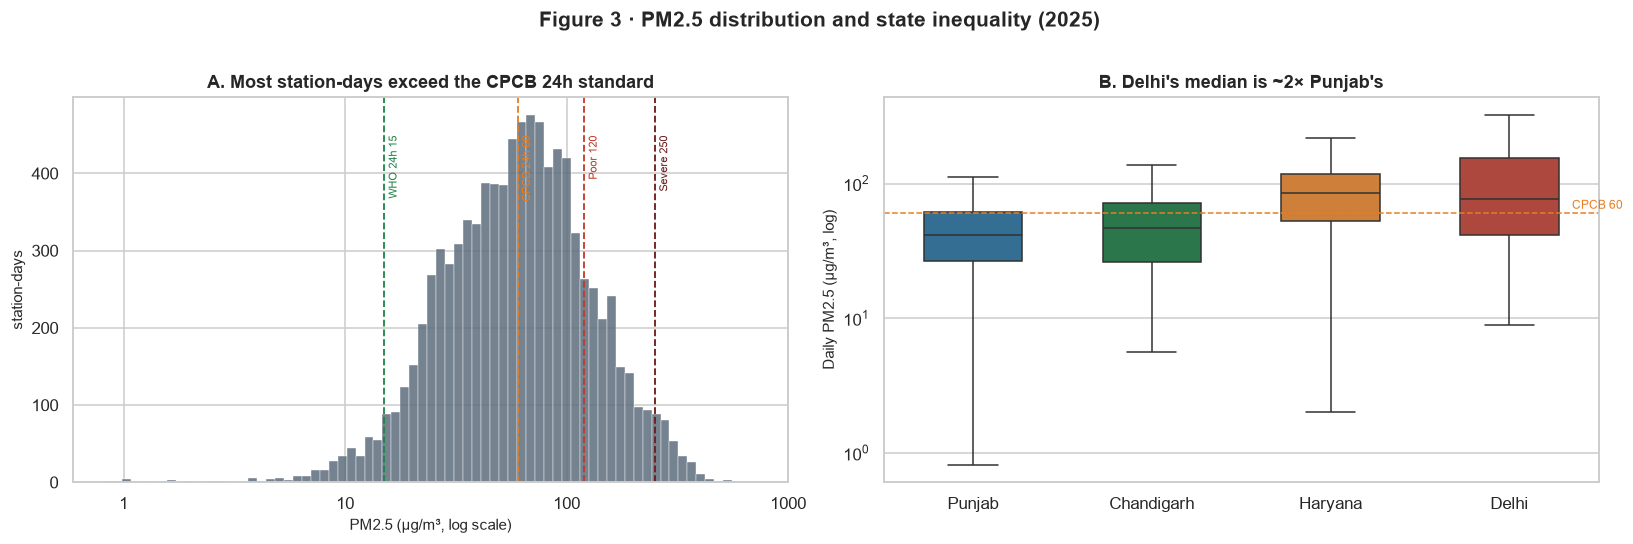

Median / mean daily PM2.5 by state


,count,median,mean,max
state,,,,
Chandigarh,976,47.0,53.4,248.5
Delhi,2157,77.1,110.3,559.5
Haryana,3394,84.9,91.1,531.4
Punjab,2652,41.7,46.2,308.5


Share of station-days above CPCB 24h standard (60 µg/m³):
state
Chandigarh    34.3
Delhi         60.1
Haryana       70.0
Punjab        26.7


In [11]:
d = daily.dropna(subset=["pm25_mean"]).copy()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
ax = axes[0]
vals = np.log10(d.pm25_mean.clip(lower=0.1))
ax.hist(vals, bins=70, color="#5d6d7e", alpha=.85, edgecolor="white", linewidth=.3)
for v, label, c in [(15,"WHO 24h 15","#1e8449"), (60,"CPCB 24h 60","#e67e22"),
                    (120,"Poor 120","#c0392b"), (250,"Severe 250","#6c1b1b")]:
    ax.axvline(np.log10(v), color=c, ls="--", lw=1.2)
    ax.text(np.log10(v)+.02, ax.get_ylim()[1]*.9, label, rotation=90, va="top", fontsize=7, color=c)
ax.set_xticks([0,1,2,3]); ax.set_xticklabels(["1","10","100","1000"])
ax.set_xlabel("PM2.5 (µg/m³, log scale)"); ax.set_ylabel("station-days")
ax.set_title("A. Most station-days exceed the CPCB 24h standard")

order = ["Punjab","Chandigarh","Haryana","Delhi"]
sns.boxplot(data=d, x="state", y="pm25_mean", order=order, palette=STATE_COLORS,
            showfliers=False, ax=axes[1], width=.55)
axes[1].set_yscale("log")
axes[1].axhline(60, color="#e67e22", ls="--", lw=1)
axes[1].text(3.35, 65, "CPCB 60", fontsize=8, color="#e67e22")
axes[1].set_xlabel(""); axes[1].set_ylabel("Daily PM2.5 (µg/m³, log)")
axes[1].set_title("B. Delhi's median is ~2× Punjab's")
fig.suptitle("Figure 3 · PM2.5 distribution and state inequality (2025)", fontsize=14, fontweight="bold", y=1.02)
fig.tight_layout(); savefig(fig, "fig03_distribution.png"); plt.show()

print("Median / mean daily PM2.5 by state")
display(d.groupby("state").pm25_mean.agg(["count","median","mean","max"]).round(1))
print("Share of station-days above CPCB 24h standard (60 µg/m³):")
print((d.assign(over=d.pm25_mean>60).groupby("state").over.mean()*100).round(1).to_string())

**Pattern 1 — a two-speed airshed.** Delhi's median daily PM2.5 is ~77 µg/m³, Punjab's ~42 µg/m³, yet Delhi's tail reaches 560 µg/m³. The distribution is right-skewed on a log scale: the same state can be "Satisfactory" one week and "Severe" the next. A single annual average hides the entire policy problem.

### 6.2 Seasonality: the November cliff

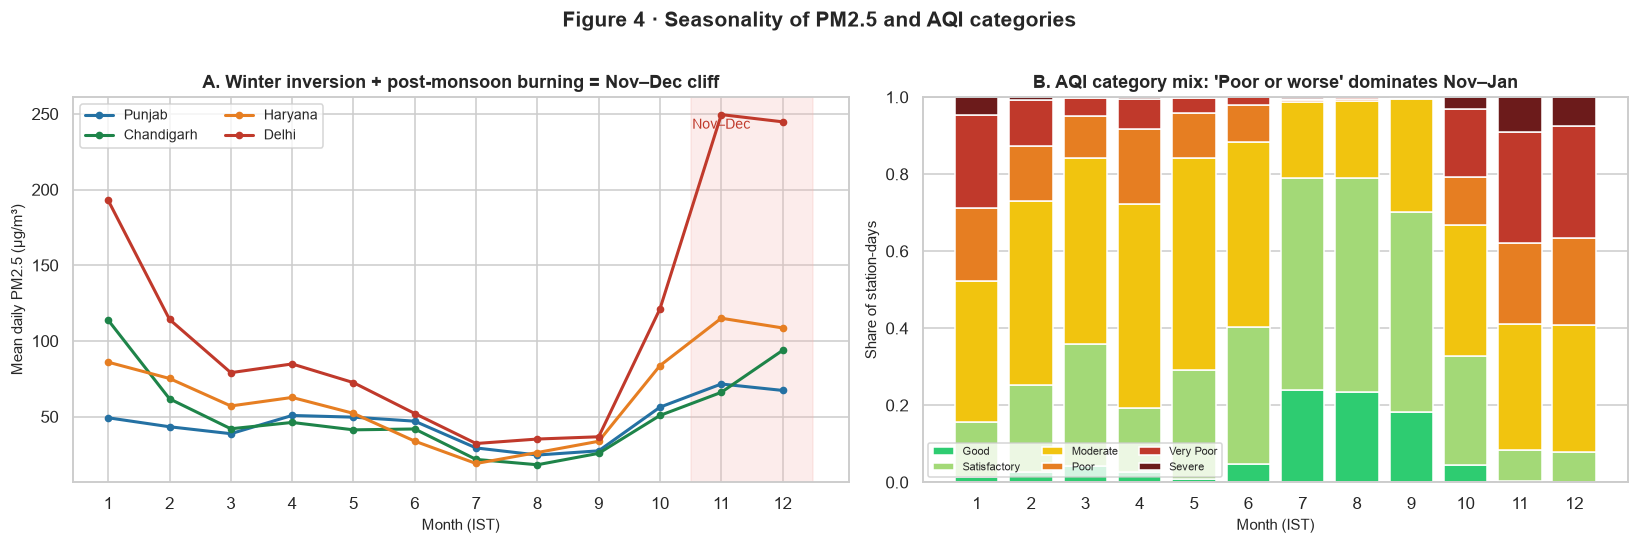

state  Chandigarh  Delhi  Haryana  Punjab
month                                    
1           113.7  192.8     86.0    49.3
2            61.8  114.2     75.2    43.3
3            42.0   79.1     57.1    38.7
4            46.2   84.8     62.7    50.8
5            41.3   72.5     52.2    49.7
6            41.9   52.1     33.8    47.0
7            21.8   32.3     19.1    29.3
8            18.2   35.2     26.3    24.7
9            25.8   36.7     33.7    27.4
10           50.8  121.2     83.7    56.3
11           66.1  249.5    115.0    71.6
12           93.8  244.7    108.6    67.3

Delhi monthly mean PM2.5 (µg/m³):
month
1     192.8
2     114.2
3      79.1
4      84.8
5      72.5
6      52.1
7      32.3
8      35.2
9      36.7
10    121.2
11    249.5
12    244.7


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios":[1.1,1]})
monthly = d.pivot_table(index="month", columns="state", values="pm25_mean", aggfunc="mean")
for s in order:
    axes[0].plot(monthly.index, monthly[s], marker="o", ms=4, lw=2,
                 color=STATE_COLORS[s], label=s)
axes[0].set_xticks(range(1,13)); axes[0].set_xlabel("Month (IST)")
axes[0].set_ylabel("Mean daily PM2.5 (µg/m³)")
axes[0].set_title("A. Winter inversion + post-monsoon burning = Nov–Dec cliff")
axes[0].axvspan(10.5, 12.5, color="#f5b7b1", alpha=.25)
axes[0].text(11, axes[0].get_ylim()[1]*.92, "Nov–Dec", ha="center", fontsize=9, color="#c0392b")
axes[0].legend(ncol=2, frameon=True)

share = (pd.crosstab(d.month, d.aqi_category, normalize="index")
         .reindex(columns=CAT_ORDER, fill_value=0))
bottom = np.zeros(len(share))
for c in CAT_ORDER:
    axes[1].bar(share.index, share[c], bottom=bottom, color=CAT_COLORS[c], label=c, width=.8)
    bottom += share[c].values
axes[1].set_xticks(range(1,13)); axes[1].set_xlabel("Month (IST)")
axes[1].set_ylabel("Share of station-days"); axes[1].set_ylim(0,1)
axes[1].set_title("B. AQI category mix: 'Poor or worse' dominates Nov–Jan")
axes[1].legend(ncol=3, fontsize=7, loc="lower left", frameon=True)
fig.suptitle("Figure 4 · Seasonality of PM2.5 and AQI categories", fontsize=14, fontweight="bold", y=1.02)
fig.tight_layout(); savefig(fig, "fig04_seasonality.png"); plt.show()

print(monthly.round(1).to_string())
print("\nDelhi monthly mean PM2.5 (µg/m³):")
print(monthly["Delhi"].round(1).to_string())

**Pattern 2 — the November cliff is real and abrupt.** Delhi's monthly mean rises from ~33 µg/m³ in July to ~250 µg/m³ in November (7.5×). Punjab rises far less (~25 → ~72). The gap between Delhi and its upwind neighbours widens exactly when the regional burning season and the winter inversion coincide. This is the signature of **local accumulation plus regional transport**, not a uniform regional increase.

### 6.3 Diurnal cycle: the 4 a.m. trap

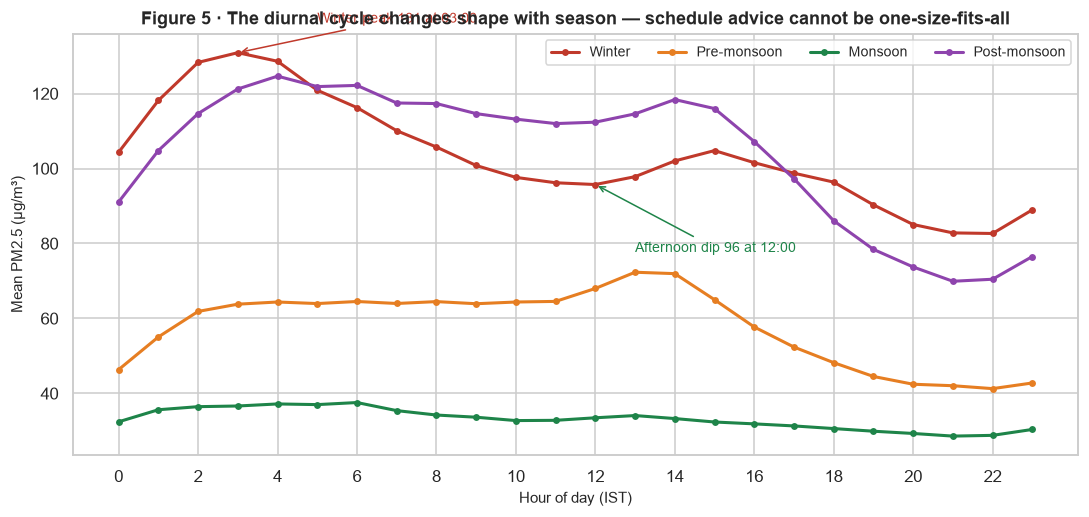

Winter diurnal summary
  peak hour : 03:00 → 130.9 µg/m³
  afternoon : 12:00 → 95.7 µg/m³
  morning 06–10 mean: 106.1
  night 00–05 mean  : 121.9


In [13]:
hourly["season"] = hourly.timestamp_ist.dt.month.map(season_of_month)
diurnal = hourly.groupby(["season","hour_ist"]).pm25.mean().unstack(0)
season_order = ["Winter","Pre-monsoon","Monsoon","Post-monsoon"]
season_colors = {"Winter":"#c0392b","Pre-monsoon":"#e67e22","Monsoon":"#1e8449","Post-monsoon":"#8e44ad"}

fig, ax = plt.subplots(figsize=(10, 4.8))
for s in season_order:
    ax.plot(diurnal.index, diurnal[s], marker="o", ms=3.5, lw=2, color=season_colors[s], label=s)
ax.set_xticks(range(0,24,2)); ax.set_xlabel("Hour of day (IST)")
ax.set_ylabel("Mean PM2.5 (µg/m³)")
ax.set_title("Figure 5 · The diurnal cycle changes shape with season — schedule advice cannot be one-size-fits-all")
ax.legend(ncol=4, frameon=True)
# annotate winter peak and afternoon dip
w = diurnal["Winter"]
peak_h = int(w.idxmax()); dip_h = int(w.loc[12:17].idxmin())
ax.annotate(f"Winter peak {w.max():.0f} at {peak_h:02d}:00",
            xy=(peak_h, w.max()), xytext=(peak_h+2, w.max()+8),
            arrowprops=dict(arrowstyle="->", color="#c0392b"), color="#c0392b", fontsize=9)
ax.annotate(f"Afternoon dip {w.loc[dip_h]:.0f} at {dip_h:02d}:00",
            xy=(dip_h, w.loc[dip_h]), xytext=(dip_h+1, w.loc[dip_h]-18),
            arrowprops=dict(arrowstyle="->", color="#1e8449"), color="#1e8449", fontsize=9)
fig.tight_layout(); savefig(fig, "fig05_diurnal.png"); plt.show()

print("Winter diurnal summary")
print("  peak hour :", f"{peak_h:02d}:00", "→", round(w.max(),1), "µg/m³")
print("  afternoon :", f"{dip_h:02d}:00", "→", round(w.loc[dip_h],1), "µg/m³")
print("  morning 06–10 mean:", round(w.loc[6:10].mean(),1))
print("  night 00–05 mean  :", round(w.loc[0:5].mean(),1))

**Pattern 3 — in winter, the worst air is at 3–5 a.m., not at rush hour.** Winter PM2.5 peaks at ~131 µg/m³ around 4 a.m., when the nocturnal boundary layer is shallowest and winds are calm, then falls to ~96 µg/m³ by late afternoon. In pre-monsoon, the afternoon is *worse* (dust and ozone chemistry). A fixed "avoid 8–10 a.m." advisory is therefore wrong for both seasons. This is the empirical basis for a **time-optimised clean-air window** rather than a single daily AQI number.

### 6.4 Wind: the winter pollution rose

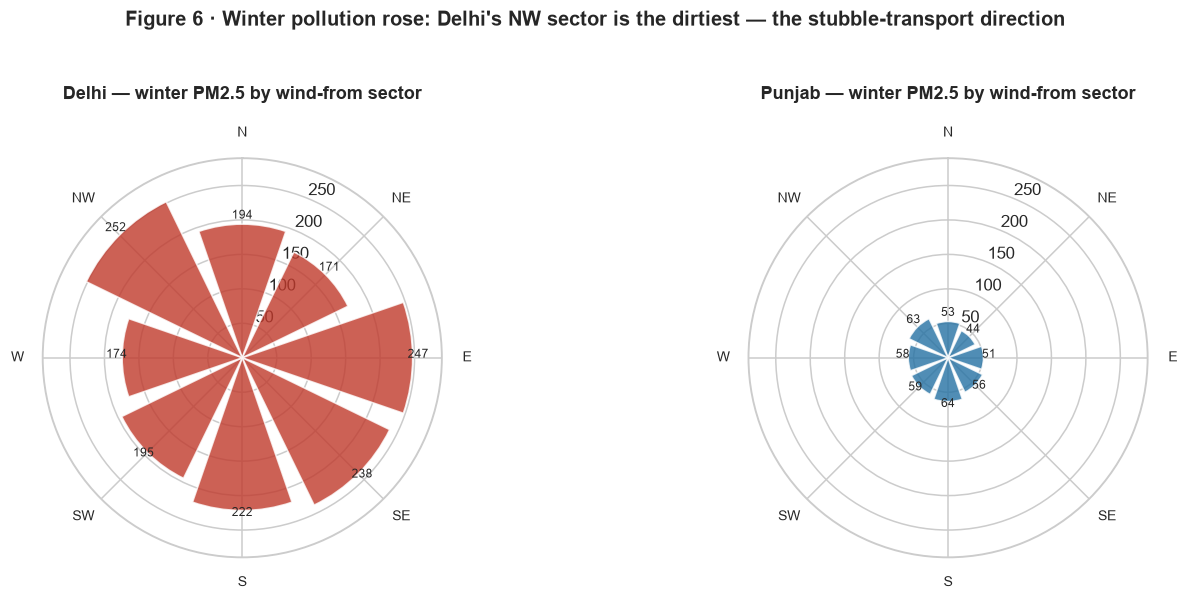

Winter mean PM2.5 by wind-from sector (µg/m³)


sector,N,NE,E,SE,S,SW,W,NW
state,,,,,,,,
Chandigarh,83.0,79.0,84.0,104.0,122.0,93.0,82.0,79.0
Delhi,194.0,171.0,247.0,238.0,222.0,195.0,174.0,252.0
Haryana,101.0,97.0,100.0,84.0,97.0,114.0,104.0,81.0
Punjab,53.0,44.0,51.0,56.0,64.0,59.0,58.0,63.0



Delhi top-decile vs bottom-decile days


,high_pollution,clean
pm,301.6,25.5
ws,0.7,1.9
temp,14.0,26.9
rh,72.5,72.7


In [14]:
d = daily.dropna(subset=["pm25_mean"]).copy()
d["wind_dir_deg"] = (np.degrees(np.arctan2(-d.wind_u_mean, -d.wind_v_mean)) + 360) % 360
sectors = ["N","NE","E","SE","S","SW","W","NW"]
def add_sector(df):
    df = df.copy()
    df["sector"] = pd.cut(df.wind_dir_deg, [0,45,90,135,180,225,270,315,360],
                          labels=sectors, include_lowest=True)
    return df
dw = add_sector(d[d.month.isin([11,12,1,2])])
rose = dw.pivot_table(index="state", columns="sector", values="pm25_mean",
                      aggfunc="mean", observed=True).reindex(columns=sectors)

fig = plt.figure(figsize=(13, 5.2))
for i, state in enumerate(["Delhi","Punjab"]):
    ax = fig.add_subplot(1, 2, i+1, projection="polar")
    vals = rose.loc[state].values.astype(float)
    theta = np.deg2rad(np.arange(8)*45)
    bars = ax.bar(theta, vals, width=np.deg2rad(38), color=STATE_COLORS[state],
                  alpha=.8, edgecolor="white")
    ax.set_theta_zero_location("N"); ax.set_theta_direction(-1)
    ax.set_xticks(theta); ax.set_xticklabels(sectors, fontsize=9)
    ax.set_title(f"{state} — winter PM2.5 by wind-from sector", pad=18)
    for t, v in zip(theta, vals):
        if not np.isnan(v):
            ax.text(t, v+8, f"{v:.0f}", ha="center", fontsize=8)
    ax.set_ylim(0, max(260, np.nanmax(rose.values)*1.15))
fig.suptitle("Figure 6 · Winter pollution rose: Delhi's NW sector is the dirtiest — the stubble-transport direction",
             fontsize=13, fontweight="bold", y=1.04)
fig.tight_layout(); savefig(fig, "fig06_pollution_rose.png"); plt.show()

print("Winter mean PM2.5 by wind-from sector (µg/m³)")
display(rose.round(0))

# top-decile vs bottom-decile Delhi days: stagnation is the dominant regime
dd = d[d.state=="Delhi"].groupby("date_ist").agg(
    pm=("pm25_mean","mean"), wd=("wind_dir_deg","mean"),
    ws=("ws_mean","mean"), temp=("temp_min","mean"), rh=("rh_mean","mean"))
hi, lo = dd[dd.pm >= dd.pm.quantile(.90)], dd[dd.pm <= dd.pm.quantile(.10)]
print("\nDelhi top-decile vs bottom-decile days")
display(pd.DataFrame({"high_pollution": hi[["pm","ws","temp","rh"]].mean(),
                      "clean": lo[["pm","ws","temp","rh"]].mean()}).round(1))

**Pattern 4 — two different bad-air regimes.** Delhi's winter NW sector averages ~217 µg/m³ (the highest of the eight sectors), consistent with transport from Punjab/Haryana. But the *top 10%* of Delhi days are dominated by **calm S/SE winds** (mean wind speed 0.7 m/s vs 1.9 m/s on clean days) and low temperatures (14 °C vs 27 °C). In other words: **transport loads the gun; stagnation pulls the trigger.** A useful advisory must distinguish "imported plume" from "local trap", because the policy response differs (regional coordination vs local traffic/dust controls).

### 6.5 Rain: the natural scrubber

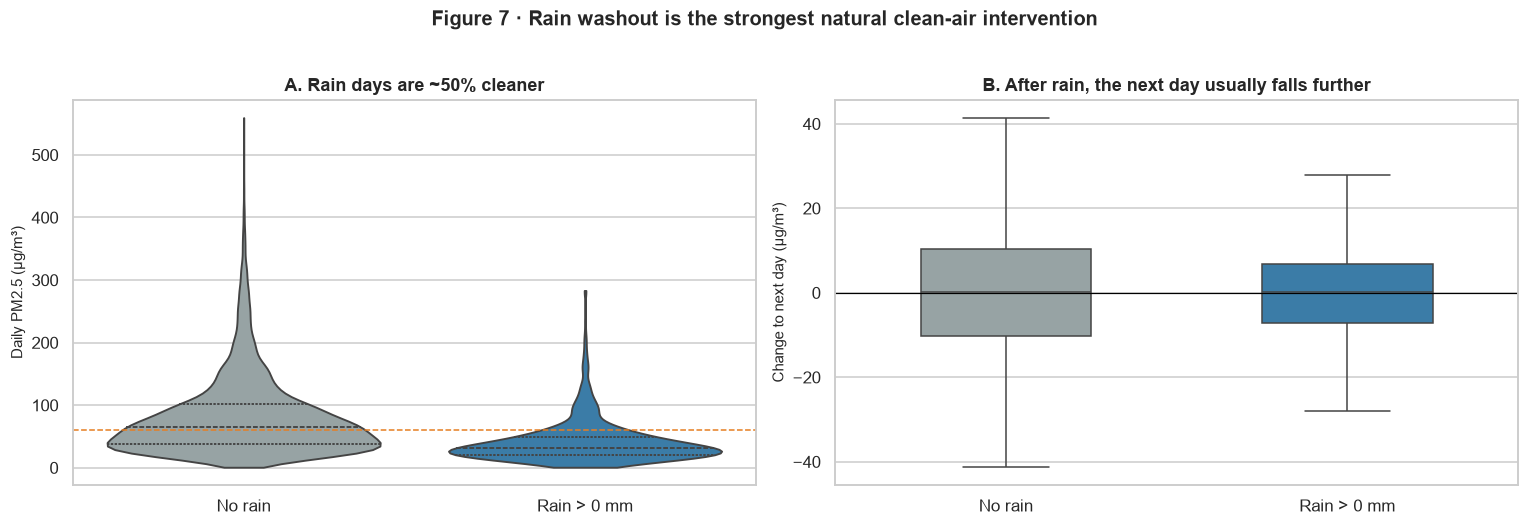

Mean PM2.5 on rain vs no-rain days:
          count  mean  median
rain_day                     
False      8480  81.7    64.8
True        699  41.9    32.1

Mean next-day change:
          count  mean  median
rain_day                     
False      8435   0.3     0.2
True        697  -0.3     0.1

Rain-day reduction vs no-rain: 48.7 %


In [15]:
d["rain_day"] = d.rain_sum > 0
d["pm25_change_next"] = d.groupby("station_id").pm25_mean.shift(-1) - d.pm25_mean

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
sns.violinplot(data=d, x="rain_day", y="pm25_mean", ax=axes[0],
               palette=["#95a5a6","#2980b9"], inner="quartile", cut=0)
axes[0].set_xticklabels(["No rain","Rain > 0 mm"])
axes[0].set_ylabel("Daily PM2.5 (µg/m³)"); axes[0].set_xlabel("")
axes[0].set_title("A. Rain days are ~50% cleaner")
axes[0].axhline(60, color="#e67e22", ls="--", lw=1)

chg = d.dropna(subset=["pm25_change_next"])
sns.boxplot(data=chg, x="rain_day", y="pm25_change_next", ax=axes[1],
            palette=["#95a5a6","#2980b9"], showfliers=False, width=.5)
axes[1].axhline(0, color="black", lw=.8)
axes[1].set_xticklabels(["No rain","Rain > 0 mm"])
axes[1].set_ylabel("Change to next day (µg/m³)"); axes[1].set_xlabel("")
axes[1].set_title("B. After rain, the next day usually falls further")
fig.suptitle("Figure 7 · Rain washout is the strongest natural clean-air intervention", fontsize=13, fontweight="bold", y=1.03)
fig.tight_layout(); savefig(fig, "fig07_rain_washout.png"); plt.show()

print("Mean PM2.5 on rain vs no-rain days:")
print(d.groupby("rain_day").pm25_mean.agg(["count","mean","median"]).round(1).to_string())
print("\nMean next-day change:")
print(chg.groupby("rain_day").pm25_change_next.agg(["count","mean","median"]).round(1).to_string())
print("\nRain-day reduction vs no-rain:", round(100*(1-d[d.rain_day].pm25_mean.mean()/d[~d.rain_day].pm25_mean.mean()),1), "%")

**Pattern 5 — rain is a natural experiment.** Rain days average ~42 µg/m³ vs ~82 µg/m³ on dry days (−49%). The next-day change is also more negative after rain. This is not a model artefact; it is the washout of particulates and the collapse of the boundary-layer trap. It also means any forecast that ignores rain events will overpredict winter episodes.

### 6.6 Pollutant mix: PM2.5 and PM10 move together

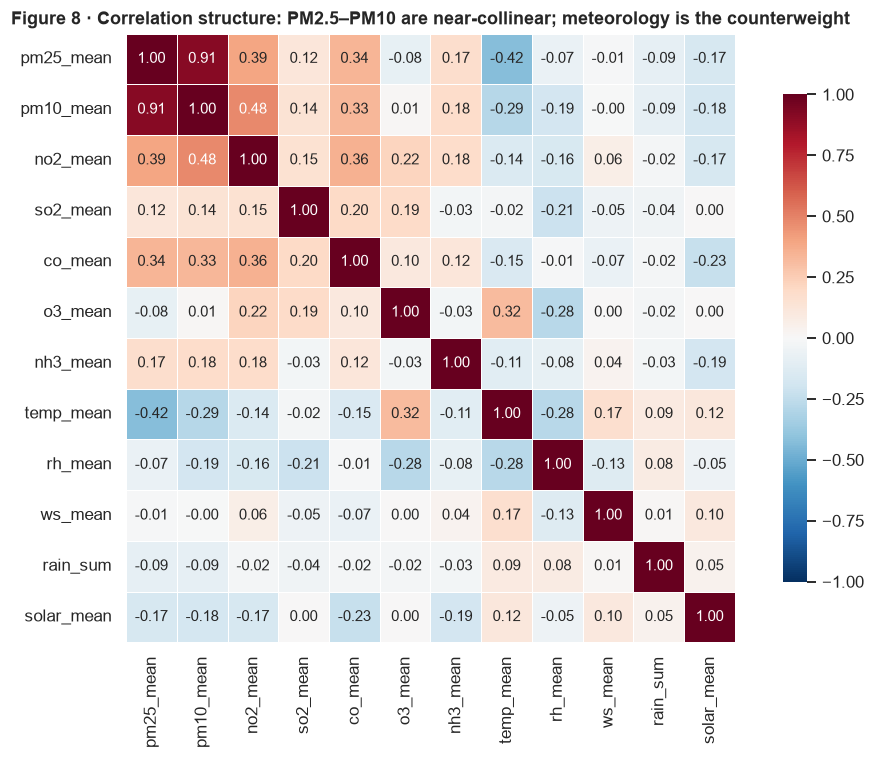

Correlation with daily PM2.5 (sorted):
pm10_mean     0.91
no2_mean      0.39
co_mean       0.34
nh3_mean      0.17
so2_mean      0.12
ws_mean      -0.01
rh_mean      -0.07
o3_mean      -0.08
rain_sum     -0.09
solar_mean   -0.17
temp_mean    -0.42


In [16]:
cols = ["pm25_mean","pm10_mean","no2_mean","so2_mean","co_mean","o3_mean","nh3_mean",
        "temp_mean","rh_mean","ws_mean","rain_sum","solar_mean"]
corr = d[cols].corr()
fig, ax = plt.subplots(figsize=(9.5, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, linewidths=.4, cbar_kws={"shrink":.8}, ax=ax)
ax.set_title("Figure 8 · Correlation structure: PM2.5–PM10 are near-collinear; meteorology is the counterweight")
fig.tight_layout(); savefig(fig, "fig08_correlation.png"); plt.show()

print("Correlation with daily PM2.5 (sorted):")
print(corr["pm25_mean"].drop("pm25_mean").sort_values(ascending=False).round(2).to_string())

**Pattern 6 — PM2.5 and PM10 are nearly the same signal (r = 0.91).** This is why a PM2.5-only model can still rank days well, but it also means the two are not independent evidence. Temperature is negatively correlated (−0.42): cold days are dirty days. Wind speed has a weak *unconditional* correlation because its effect is nonlinear and interacts with direction; the model uses both speed and u/v components.

### 6.7 The long view: 2017–2023 and the COVID dip

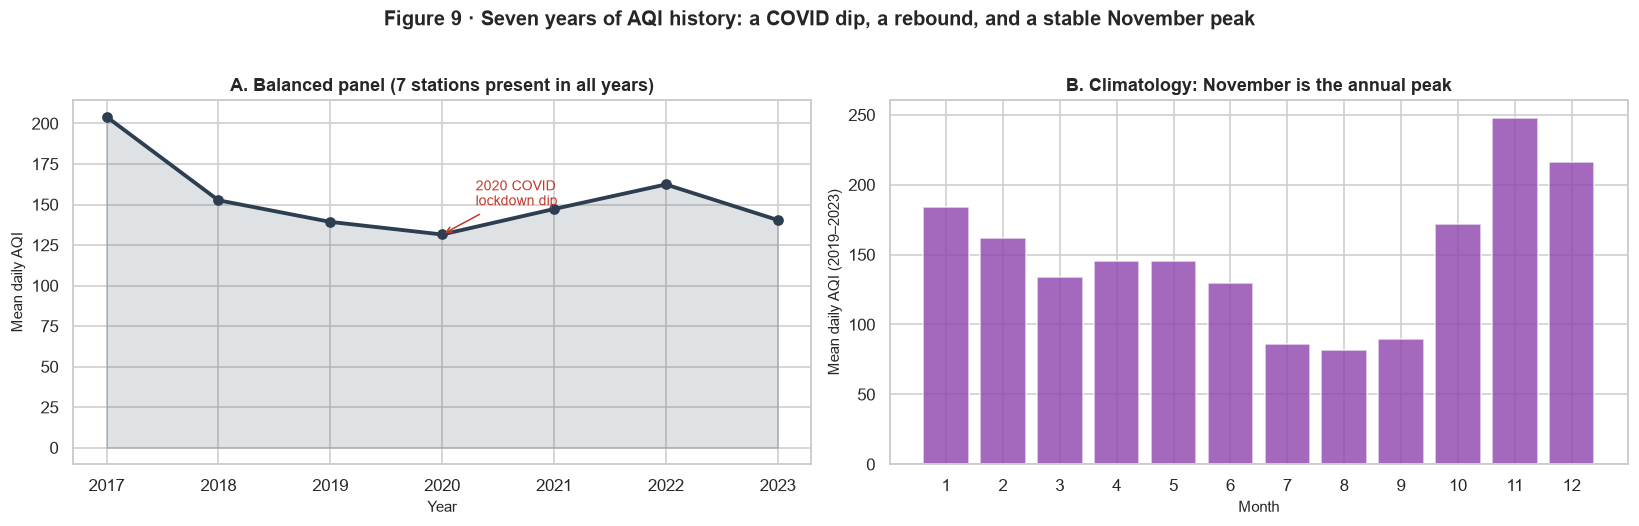

Balanced annual mean AQI:
year
2017    204.1
2018    152.6
2019    139.3
2020    131.5
2021    147.2
2022    162.4
2023    140.4

2019→2020 change: -7.8 | 2020→2022 rebound: 30.9

Monthly climatology 2019–2023:
month
1     184.1
2     161.7
3     134.0
4     145.5
5     145.4
6     129.9
7      86.4
8      81.8
9      89.3
10    172.0
11    248.1
12    216.4


In [17]:
hours = [f"{i:02d}:00:00" for i in range(24)]
hist_long = hist_mapped.melt(id_vars=["station_id","date"], value_vars=hours,
                             var_name="hour", value_name="aqi")
hist_long["hour"] = hist_long.hour.str[:2].astype(int)
hist_long = hist_long.dropna(subset=["aqi"])
hist_daily = (hist_long.groupby(["station_id","date"])
              .agg(hist_aqi_mean=("aqi","mean"), hist_aqi_max=("aqi","max"),
                   hist_hours=("aqi","size")).reset_index())
hist_daily["year"] = hist_daily.date.dt.year
hist_daily["month"] = hist_daily.date.dt.month
hist_daily["doy"] = hist_daily.date.dt.dayofyear

piv = hist_daily.pivot_table(index="station_id", columns="year",
                             values="hist_aqi_mean", aggfunc="mean")
bal = piv.dropna()
annual = bal.mean()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
axes[0].plot(annual.index, annual.values, marker="o", lw=2.5, color="#2c3e50")
axes[0].fill_between(annual.index, annual.values, alpha=.15, color="#2c3e50")
axes[0].set_xticks(annual.index); axes[0].set_xlabel("Year")
axes[0].set_ylabel("Mean daily AQI")
axes[0].set_title(f"A. Balanced panel ({len(bal)} stations present in all years)")
axes[0].annotate("2020 COVID\nlockdown dip", xy=(2020, annual.loc[2020]),
                 xytext=(2020.3, annual.loc[2020]+18),
                 arrowprops=dict(arrowstyle="->", color="#c0392b"), color="#c0392b", fontsize=9)

mon = hist_daily[hist_daily.year >= 2019].groupby("month").hist_aqi_mean.mean()
axes[1].bar(mon.index, mon.values, color="#8e44ad", alpha=.8)
axes[1].set_xticks(range(1,13)); axes[1].set_xlabel("Month")
axes[1].set_ylabel("Mean daily AQI (2019–2023)")
axes[1].set_title("B. Climatology: November is the annual peak")
fig.suptitle("Figure 9 · Seven years of AQI history: a COVID dip, a rebound, and a stable November peak",
             fontsize=13, fontweight="bold", y=1.03)
fig.tight_layout(); savefig(fig, "fig09_history_trend.png"); plt.show()

print("Balanced annual mean AQI:")
print(annual.round(1).to_string())
print("\n2019→2020 change:", round(annual.loc[2020]-annual.loc[2019],1),
      "| 2020→2022 rebound:", round(annual.loc[2022]-annual.loc[2020],1))
print("\nMonthly climatology 2019–2023:")
print(mon.round(1).to_string())

**Pattern 7 — the long trend is not a straight line.** On a balanced 7-station panel, AQI falls from ~204 in 2017 to ~132 in 2020 (COVID), rebounds to ~162 in 2022, then eases to ~140 in 2023. The 2020 dip is a natural experiment: mobility and industry fell, and AQI followed. The rebound is a warning that structural change, not just weather, drives the level. November remains the peak in every year (mean AQI ~248).

### 6.8 Exposure inequality: the "breathing debt"

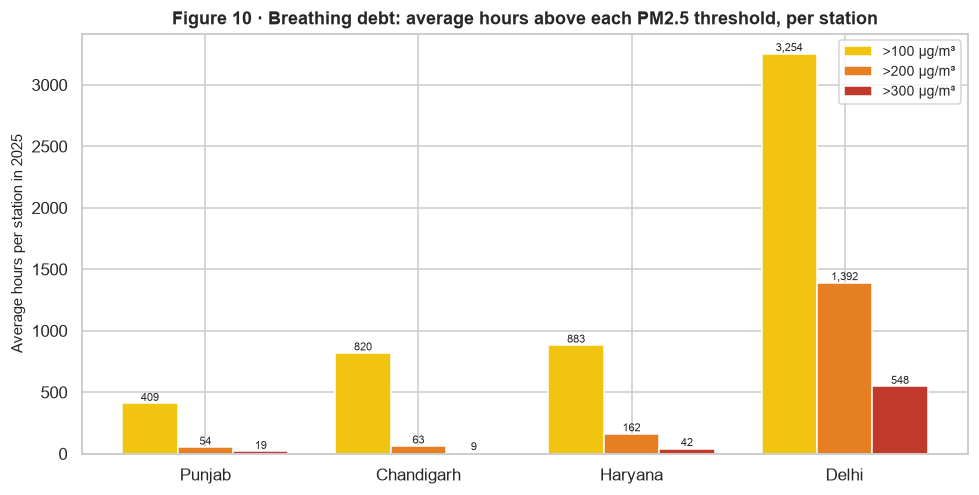

Average hours per station above threshold (2025)


,stations,hours_gt_100,hours_gt_200,hours_gt_300
state,,,,
Punjab,8,409.0,54.0,19.0
Chandigarh,3,820.0,63.0,9.0
Haryana,30,883.0,162.0,42.0
Delhi,6,3254.0,1392.0,548.0



Caveat: Haryana's number is biased downward by its missing summer data; Delhi's is the most complete.


In [18]:
thresholds = [100, 200, 300]
debt = []
for state, g in hourly.dropna(subset=["pm25"]).groupby("state"):
    n_st = g.station_id.nunique()
    row = {"state": state, "stations": n_st}
    for t in thresholds:
        row[f"hours_gt_{t}"] = (g.pm25 > t).sum() / n_st   # per-station average
    debt.append(row)
debt = pd.DataFrame(debt).set_index("state").loc[["Punjab","Chandigarh","Haryana","Delhi"]]

fig, ax = plt.subplots(figsize=(9, 4.6))
x = np.arange(len(debt)); w = .26
for i, t in enumerate(thresholds):
    ax.bar(x + (i-1)*w, debt[f"hours_gt_{t}"], width=w,
           label=f">{t} µg/m³", color=["#f1c40f","#e67e22","#c0392b"][i])
ax.set_xticks(x); ax.set_xticklabels(debt.index)
ax.set_ylabel("Average hours per station in 2025")
ax.set_title("Figure 10 · Breathing debt: average hours above each PM2.5 threshold, per station")
ax.legend(frameon=True)
for i, t in enumerate(thresholds):
    for j, v in enumerate(debt[f"hours_gt_{t}"]):
        ax.text(j + (i-1)*w, v+20, f"{v:,.0f}", ha="center", fontsize=7)
fig.tight_layout(); savefig(fig, "fig10_breathing_debt.png"); plt.show()

print("Average hours per station above threshold (2025)")
display(debt.round(0))
print("\nCaveat: Haryana's number is biased downward by its missing summer data; Delhi's is the most complete.")

**Pattern 8 — Delhi carries a disproportionate "breathing debt".** Per station, Delhi records ~3,254 hours above 100 µg/m³, ~1,392 above 200 and ~548 above 300. That is roughly **23 days of "Very Poor or worse" air per station**, versus ~19 hours above 300 in Punjab. Haryana's lower number is partly a missing-data artefact — a reminder that coverage itself is an equity issue.

### 6.9 Transport vs stagnation: the plume bridge

In [19]:
# Approximate city/station coordinates (station-level where known, city centroid otherwise).
# These are used only for regional transport geometry, not for hyperlocal mapping.
COORDS = {
"site_5491":(30.7333,76.7794),"site_5127":(30.7280,76.7750),"site_5582":(30.7150,76.7550),
"site_1420":(28.6953,77.1810),"site_1422":(28.5710,77.0710),"site_1426":(28.8520,77.0930),
"site_1429":(28.5670,77.2530),"site_1431":(28.6230,77.2920),"site_1434":(28.6990,77.1650),
"site_5052":(30.3782,76.7767),"site_5045":(28.6926,76.9355),"site_5060":(28.3404,77.3234),
"site_5047":(28.7975,76.1322),"site_5339":(28.5917,76.2711),"site_5044":(28.2053,76.7993),
"site_5340":(28.3830,77.3000),"site_5342":(28.3940,77.3270),"site_5341":(28.4200,77.3300),
"site_263":(28.4089,77.3178),"site_5054":(29.5159,75.4555),"site_5025":(28.4300,77.1000),
"site_5345":(28.4300,77.0600),"site_5344":(28.4200,77.0500),"site_146":(28.4595,77.0266),
"site_5057":(29.1492,75.7217),"site_5056":(29.3157,76.3151),"site_5072":(29.8015,76.3996),
"site_5049":(29.6857,76.9905),"site_5043":(29.9695,76.8783),"site_5055":(28.1000,77.0000),
"site_5039":(28.3546,76.9366),"site_5053":(28.0444,76.1086),"site_5050":(28.1487,77.3320),
"site_6011":(28.3150,76.8950),"site_161":(30.6942,76.8606),"site_5048":(29.3909,76.9635),
"site_147":(28.8955,76.6066),"site_5051":(29.5349,75.0280),"site_5041":(28.9931,77.0151),
"site_5046":(30.1290,77.2674),"site_256":(31.6340,74.8723),"site_1549":(30.2110,74.9455),
"site_1438":(31.3260,75.5762),"site_1450":(30.7046,76.2154),"site_253":(30.9010,75.8573),
"site_255":(30.6700,76.2900),"site_1437":(30.3398,76.3869),"site_1538":(30.9686,76.5270)}
coord_df = pd.DataFrame([(k, v[0], v[1]) for k, v in COORDS.items()],
                        columns=["station_id","lat","lon"])
daily = daily.merge(coord_df, on="station_id", how="left")

sids = list(COORDS)
dist = pd.DataFrame(index=sids, columns=sids, dtype=float)
brg  = pd.DataFrame(index=sids, columns=sids, dtype=float)
for a in sids:
    for b in sids:
        dist.loc[a,b] = haversine(*COORDS[a], *COORDS[b]) if a != b else 0.0
        brg.loc[a,b]  = bearing(*COORDS[a], *COORDS[b]) if a != b else 0.0

daily["wind_dir_deg"] = (np.degrees(np.arctan2(-daily.wind_u_mean, -daily.wind_v_mean)) + 360) % 360
daily["wind_vec_mag"] = np.hypot(daily.wind_u_mean, daily.wind_v_mean)

P = daily.pivot(index="date_ist", columns="station_id", values="pm25_mean")
up = np.full((len(daily), 3), np.nan)
reg = np.full((len(daily), 3), np.nan)
for i, row in enumerate(daily.itertuples()):
    sid, date = row.station_id, row.date_ist
    if sid not in COORDS or pd.isna(row.wind_dir_deg):
        continue
    wd = row.wind_dir_deg
    for lag in range(3):
        dd_ = date - pd.Timedelta(days=lag)
        if dd_ not in P.index:
            continue
        vals, wts, allv = [], [], []
        for sid2 in sids:
            if sid2 == sid: continue
            dkm = dist.loc[sid, sid2]
            if dkm > 450: continue
            v = P.at[dd_, sid2]
            if pd.isna(v): continue
            allv.append(v)
            if 15 <= dkm <= 400:
                ang = abs((wd - brg.loc[sid, sid2] + 180) % 360 - 180)
                if ang <= 55:
                    vals.append(v)
                    wts.append(np.cos(radians(ang))**2 * np.exp(-dkm/250))
        if wts:
            up[i, lag] = np.average(vals, weights=wts)
        if allv:
            reg[i, lag] = np.mean(allv)

daily[["upwind_pm25_d0","upwind_pm25_d1","upwind_pm25_d2"]] = up
daily[["regional_pm25_d0","regional_pm25_d1","regional_pm25_d2"]] = reg
daily["upwind_minus_local"] = daily.upwind_pm25_d0 - daily.pm25_mean
daily["stagnation"] = 1 / (daily.ws_mean + 0.2)
daily["transport_index"] = daily.upwind_pm25_d0 / daily.pm25_mean.clip(lower=1)
daily["regime"] = np.select(
    [(daily.ws_mean < 0.8) & (daily.transport_index < 0.8),
     (daily.ws_mean >= 0.8) & (daily.transport_index > 1.1)],
    ["Local stagnation", "Regional transport"], default="Mixed")

print("Regime counts (station-days):")
print(daily.regime.value_counts(dropna=False).to_string())
print("\nDelhi: correlation of PM2.5 with upwind PM2.5, by wind speed")
dd = daily[daily.state=="Delhi"].dropna(subset=["upwind_pm25_d0","pm25_mean","ws_mean"])
for label, mask in [("calm < 1 m/s", dd.ws_mean < 1), ("windy ≥ 1 m/s", dd.ws_mean >= 1)]:
    print(f"  {label:14s} r = {dd[mask][['pm25_mean','upwind_pm25_d0']].corr().iloc[0,1]:.3f}  (n={mask.sum()})")

Regime counts (station-days):
regime
Mixed                 14976
Regional transport     1398
Local stagnation       1146

Delhi: correlation of PM2.5 with upwind PM2.5, by wind speed
  calm < 1 m/s   r = 0.841  (n=807)
  windy ≥ 1 m/s  r = 0.863  (n=908)


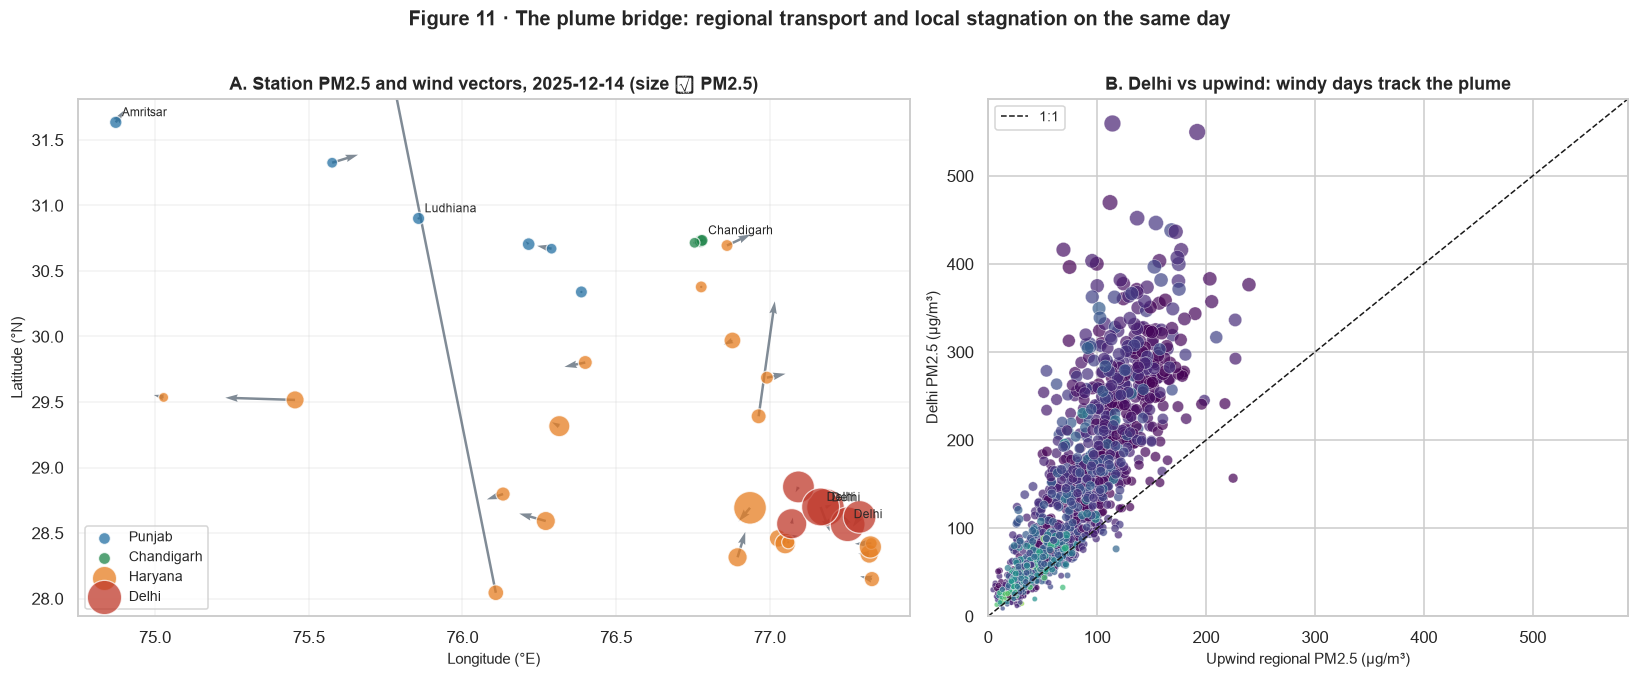

Top 10 regional PM2.5 days (mean across stations):


,regional_mean
date_ist,
2025-10-21,186.1
2025-12-14,161.4
2025-11-12,159.7
2025-01-10,158.3
2025-12-13,156.3
2025-01-15,156.3
2025-11-11,153.8
2025-11-13,148.4
2025-12-15,147.4


In [20]:
# Episode map: 14 Dec 2025 — one of the worst regional days of the year
ep_date = pd.Timestamp("2025-12-14")
ep = daily[daily.date_ist == ep_date].dropna(subset=["pm25_mean","wind_u_mean","wind_v_mean"]).copy()

fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios":[1.3,1]})
ax = axes[0]
for s in ["Punjab","Chandigarh","Haryana","Delhi"]:
    sub = ep[ep.state == s]
    ax.scatter(sub.lon, sub.lat, s=np.clip(sub.pm25_mean, 10, 600)*1.1,
               color=STATE_COLORS[s], alpha=.75, edgecolor="white", linewidth=.8, label=s, zorder=3)
ax.quiver(ep.lon, ep.lat, ep.wind_u_mean, ep.wind_v_mean,
          color="#2c3e50", alpha=.6, scale=35, width=.003, zorder=2)
for _, r in ep.iterrows():
    if r.station_id in ("site_1434","site_1429","site_1420","site_253","site_256","site_5491","site_5046","site_147"):
        ax.annotate(r.city, (r.lon, r.lat), xytext=(4,4), textcoords="offset points", fontsize=8)
ax.set_xlabel("Longitude (°E)"); ax.set_ylabel("Latitude (°N)")
ax.set_title(f"A. Station PM2.5 and wind vectors, {ep_date.date()} (size ∝ PM2.5)")
ax.legend(loc="lower left", frameon=True); ax.grid(alpha=.25)

ax = axes[1]
sns.scatterplot(data=dd, x="upwind_pm25_d0", y="pm25_mean", hue="ws_mean",
                palette="viridis", size="pm25_mean", sizes=(10,120), alpha=.7,
                ax=ax, legend=False)
lim = [0, max(dd.upwind_pm25_d0.max(), dd.pm25_mean.max())*1.05]
ax.plot(lim, lim, "k--", lw=1, label="1:1")
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("Upwind regional PM2.5 (µg/m³)"); ax.set_ylabel("Delhi PM2.5 (µg/m³)")
ax.set_title("B. Delhi vs upwind: windy days track the plume")
ax.legend(frameon=True)
fig.suptitle("Figure 11 · The plume bridge: regional transport and local stagnation on the same day",
             fontsize=13, fontweight="bold", y=1.02)
fig.tight_layout(); savefig(fig, "fig11_transport_map.png"); plt.show()

print("Top 10 regional PM2.5 days (mean across stations):")
display(daily.groupby("date_ist").pm25_mean.mean().sort_values(ascending=False).head(10).round(1).to_frame("regional_mean"))

**Pattern 9 — the same episode contains both mechanisms.** On 14 Dec 2025, the regional mean reached ~175 µg/m³. The map shows high PM2.5 across Punjab, Haryana and Delhi with north-westerly flow; the scatter shows Delhi tracking upwind concentrations more closely when winds are stronger. But the very worst Delhi days are calm, when the city is its own source. This dual signature is the core of the proposed solution: **forecast the plume, but also detect the trap.**

### 6.10 A short synthesis of the EDA

| # | Hidden pattern | Evidence | Why it matters |
|---|---|---|---|
| 1 | Missingness is structural | 43.6% all-pollutant blank; Haryana 5% summer coverage | Any state comparison must be coverage-aware |
| 2 | November cliff | Delhi 33 → 250 µg/m³ Jul → Nov | Policy window is Oct–Dec, not annual |
| 3 | 4 a.m. winter peak | Winter peak 131 at 04:00; afternoon 96 | Fixed rush-hour advice is wrong |
| 4 | NW transport + calm trap | NW winter sector 217; top-decile days wind 0.7 m/s | Two regimes need two policy responses |
| 5 | Rain washout | −49% on rain days | Rain is a natural clean-air intervention |
| 6 | PM2.5–PM10 collinearity | r = 0.91 | Don't double-count as independent evidence |
| 7 | COVID dip + rebound | 2019 139 → 2020 132 → 2022 162 | Structural, not just weather |
| 8 | Breathing debt | Delhi 548 h/station >300 | Exposure inequality is huge |
| 9 | Plume + trap coexist | 14 Dec map + wind-speed split | Source-aware advisory is feasible |

<a id="7-forecasting"></a>
## 7. Forecasting: accuracy against baselines

### 7.1 What we predict, and the honest split

- **Target:** next-day mean PM2.5 at the same station (24-hour-ahead forecast issued at 23:00 IST).
- **Train:** 1 Jan – 30 Sep 2025.
- **Validation:** October 2025 (used for early stopping and blend weights).
- **Test:** 1 Nov – 31 Dec 2025 — the pollution season, never seen in training.
- **Baselines:** persistence (tomorrow = today), seasonal prior from 2017–2023, and lag-1.

A direct model trained on Jan–Sep cannot extrapolate to Nov–Dec: we measured **R² = −0.12** for that naive approach. The fix is a **seasonal prior + residual/ratio model**: the 2017–2023 history supplies the winter level, and the 2025 model learns the anomaly around it.

In [21]:
daily = daily.sort_values(["station_id","date_ist"]).reset_index(drop=True)
daily["month"] = daily.date_ist.dt.month
daily["doy"] = daily.date_ist.dt.dayofyear
daily["dow"] = daily.date_ist.dt.dayofweek
daily["is_weekend"] = (daily.dow >= 5).astype(int)
daily["doy_sin"] = np.sin(2*np.pi*daily.doy/365)
daily["doy_cos"] = np.cos(2*np.pi*daily.doy/365)
daily["winter_index"] = np.cos(2*np.pi*(daily.doy-15)/365)
daily["wind_sin"] = np.sin(np.deg2rad(daily.wind_dir_deg))
daily["wind_cos"] = np.cos(np.deg2rad(daily.wind_dir_deg))

g = daily.groupby("station_id", group_keys=False)
for c in ["pm25_mean","aqi","pm10_mean","no2_mean","so2_mean","co_mean","o3_mean"]:
    for l in [1,2,3,5,7,14,21,28]:
        daily[f"{c}_lag{l}"] = g[c].shift(l)
    for w in [3,7,14,28]:
        daily[f"{c}_roll{w}"] = g[c].shift(1).rolling(w, min_periods=max(2, w//2)).mean()
for c in ["temp_mean","temp_min","rh_mean","ws_mean","rain_sum","solar_mean","pressure_mean","calm_frac"]:
    daily[f"{c}_lag1"] = g[c].shift(1)
daily["pm25_next"] = g["pm25_mean"].shift(-1)
daily["aqi_next"] = g["aqi"].shift(-1)
daily["cat_next"] = g["aqi_category"].shift(-1)
daily["tier_next"] = daily.aqi_next.map(tier_of)
daily["target_ratio"] = np.nan  # filled after seasonal priors are merged

print("Daily feature frame:", daily.shape)
print("Rows with next-day PM2.5 and current PM2.5:", daily.dropna(subset=["pm25_next","pm25_mean"]).shape[0])

Daily feature frame: (17520, 169)
Rows with next-day PM2.5 and current PM2.5: 8727


In [22]:
# ---------- history seasonal priors (day-of-year, ±7-day window, 2019–2023) ----------
hist_daily["doy"] = hist_daily.date.dt.dayofyear
h_use = hist_daily[hist_daily.year >= 2019].copy()

def circ_dist(a, b):
    d = np.abs(a - b)
    return np.minimum(d, 365 - d)

priors = []
for sid, gg in h_use.groupby("station_id"):
    for doy in range(1, 366):
        mask = circ_dist(gg.doy.values, doy) <= 7
        vals = gg.hist_aqi_mean.values[mask]
        vals = vals[~np.isnan(vals)]
        if len(vals) >= 20:
            priors.append((sid, doy, np.mean(vals), np.median(vals), len(vals)))
pri = pd.DataFrame(priors, columns=["station_id","doy","prior_aqi","prior_aqi_med","prior_n"])
pri["state"] = pri.station_id.map(stations.set_index("station_id").state)
state_pri = pri.groupby(["state","doy"]).agg(prior_aqi_state=("prior_aqi","mean")).reset_index()
glob_pri = pri.groupby("doy").prior_aqi.mean().rename("prior_aqi_global").reset_index()
pri = pri.merge(state_pri, on=["state","doy"], how="left").merge(glob_pri, on="doy", how="left")
pri["prior_aqi_final"] = pri.prior_aqi.fillna(pri.prior_aqi_state).fillna(pri.prior_aqi_global)
pri["prior_pm25"] = pri.prior_aqi_final.map(aqi_to_pm25)

pri_next = pri[["station_id","doy","prior_pm25","prior_aqi_final"]].copy()
pri_next["doy"] = (pri_next.doy % 365) + 1
pri_next = pri_next.rename(columns={"prior_pm25":"prior_pm25_next","prior_aqi_final":"prior_aqi_next"})

daily = daily.merge(pri[["station_id","doy","prior_aqi_final","prior_pm25"]],
                    on=["station_id","doy"], how="left")
daily = daily.merge(pri_next[["station_id","doy","prior_pm25_next","prior_aqi_next"]],
                    on=["station_id","doy"], how="left")
for c in ["prior_aqi_final","prior_pm25","prior_pm25_next","prior_aqi_next"]:
    daily[c] = daily[c].fillna(daily.groupby("doy")[c].transform("mean"))
    daily[c] = daily[c].fillna(daily[c].mean())

daily["prior_ratio_today"] = daily.pm25_mean / daily.prior_pm25.clip(lower=5)
daily["prior_aqi_ratio_today"] = daily.aqi / daily.prior_aqi_final.clip(lower=20)

# station-level history summaries
hist_feat = hist_daily.groupby("station_id").agg(
    hist_mean_aqi=("hist_aqi_mean","mean"),
    hist_p90_aqi=("hist_aqi_mean", lambda x: x.quantile(.90)),
    hist_max_aqi=("hist_aqi_max","max"),
    hist_days=("hist_aqi_mean","size")).reset_index()
for name, months in {"winter":[11,12,1,2], "postmon":[10,11], "monsoon":[7,8,9], "summer":[3,4,5,6]}.items():
    tmp = (hist_daily[hist_daily.month.isin(months)].groupby("station_id")
           .hist_aqi_mean.mean().rename("hist_" + name + "_aqi"))
    hist_feat = hist_feat.merge(tmp, on="station_id", how="left")
tr_hist = hist_daily.groupby(["station_id","year"]).hist_aqi_mean.mean().reset_index()
tr_hist["yr"] = tr_hist.year - 2017
slopes = []
for sid, gg in tr_hist.groupby("station_id"):
    if len(gg) >= 4:
        slopes.append((sid, np.polyfit(gg.yr, gg.hist_aqi_mean, 1)[0]))
hist_feat = hist_feat.merge(pd.DataFrame(slopes, columns=["station_id","hist_trend_per_year"]),
                            on="station_id", how="left")
daily = daily.merge(hist_feat, on="station_id", how="left")

print("Prior rows:", len(pri), "| stations:", pri.station_id.nunique())
print("History summary rows:", len(hist_feat))
print("Missing prior after fallback:", daily.prior_pm25_next.isna().sum())

daily["target_ratio"] = (daily.pm25_next / daily.prior_pm25_next.clip(lower=5)).clip(0.2, 6)

Prior rows: 14563 | stations: 40
History summary rows: 40
Missing prior after fallback: 0


**Why a seasonal prior?** A tree model cannot output a value it has never seen. November–December PM2.5 is 3–5× the January–September mean, so a direct model collapses to the training mean (we measured R² = −0.12). The prior gives the model a *known seasonal level* from seven years of history; the model then predicts whether tomorrow will be above or below that level. This is a standard **climatology + anomaly** decomposition, not a leak: all history is pre-2025.

In [23]:
exclude = {"date_ist","station_id","state","city","station_name","timestamp_utc","timestamp_ist",
           "aqi_category","cat_next","tier_next","pm25_next","aqi_next","target_ratio",
           "hour_ist","coverage","n_obs","n_pm25","pm25_p90","pm25_max","o3_8h_max","co_8h_max",
           "si_pm25","si_pm10","si_no2","si_o3","si_co","si_so2","si_nh3","aqi_official","aqi_n",
           "hist_cat","hist_aqi_mean","hist_aqi_max","hist_hours","prior_aqi_med","prior_n",
           "prior_aqi_final","prior_pm25","prior_pm25_next","prior_aqi_next","regime","tier"}
feat = [c for c in daily.columns if c not in exclude and daily[c].dtype != object]
print("Model features:", len(feat))

df = daily.dropna(subset=["pm25_next","pm25_mean"]).copy()
tr = df[df.date_ist <  "2025-10-01"]
va = df[(df.date_ist >= "2025-10-01") & (df.date_ist < "2025-11-01")]
te = df[df.date_ist >= "2025-11-01"]

print(f"Train {len(tr):,} | Validation {len(va):,} | Test {len(te):,}")
print(f"Test actual mean {te.pm25_next.mean():.1f} µg/m³ | persistence mean {te.pm25_mean.mean():.1f} | seasonal prior {te.prior_pm25_next.mean():.1f}")
display(te.groupby("state").pm25_next.agg(["count","mean","median"]).round(1))

Model features: 150
Train 5,190 | Validation 1,036 | Test 2,501
Test actual mean 122.0 µg/m³ | persistence mean 121.7 | seasonal prior 102.6


,count,mean,median
state,,,
Chandigarh,165,80.5,76.2
Delhi,360,247.8,249.6
Haryana,1555,111.4,100.9
Punjab,421,70.2,68.0


In [24]:
def baseline_table(te, tr):
    rows = []
    for name, pred in [
        ("Persistence (tomorrow = today)", te.pm25_mean),
        ("Seasonal prior (2017–2023)", te.prior_pm25_next),
        ("Lag-1 day", te.pm25_mean_lag1),
        ("Train station mean", te.station_id.map(tr.groupby("station_id").pm25_next.mean()).fillna(tr.pm25_next.mean())),
    ]:
        m = reg_metrics(te.pm25_next, pred)
        rows.append({"model": name, **m})
    return pd.DataFrame(rows)

base_tbl = baseline_table(te, tr)
display(base_tbl.round(2))

,model,R2,MAE,RMSE,Bias,n
0,Persistence (tomorrow = today),0.71,24.82,39.95,-0.33,2501
1,Seasonal prior (2017–2023),-0.02,50.18,75.07,-19.47,2501
2,Lag-1 day,0.53,32.75,51.43,-0.63,2412
3,Train station mean,-0.52,66.34,91.84,-63.18,2501


In [25]:
params = dict(objective="regression", learning_rate=0.03, num_leaves=31,
              min_child_samples=20, subsample=.8, colsample_bytree=.8,
              reg_lambda=1.0, n_estimators=1500, random_state=42, verbose=-1)

# Model A: predict the CHANGE (tomorrow - today). This is the hardest but most honest target.
mdl_delta = lgb.LGBMRegressor(**params)
mdl_delta.fit(tr[feat], tr.pm25_next - tr.pm25_mean,
              eval_set=[(va[feat], va.pm25_next - va.pm25_mean)],
              eval_metric="mae",
              callbacks=[lgb.early_stopping(100, verbose=False), lgb.log_evaluation(0)])

# Model B: predict the RATIO to the seasonal prior.
mdl_ratio = lgb.LGBMRegressor(**params)
mdl_ratio.fit(tr[feat], tr.target_ratio,
              eval_set=[(va[feat], va.target_ratio)],
              eval_metric="mae",
              callbacks=[lgb.early_stopping(100, verbose=False), lgb.log_evaluation(0)])

# Model C: direct level (for comparison / ensemble diversity).
mdl_level = lgb.LGBMRegressor(**params)
mdl_level.fit(tr[feat], tr.pm25_next,
              eval_set=[(va[feat], va.pm25_next)],
              eval_metric="mae",
              callbacks=[lgb.early_stopping(100, verbose=False), lgb.log_evaluation(0)])

def components(d):
    return np.vstack([
        d.pm25_mean.values,
        mdl_delta.predict(d[feat]) + d.pm25_mean.values,
        mdl_ratio.predict(d[feat]) * d.prior_pm25_next.values,
        mdl_level.predict(d[feat]),
    ]).T

V, T = components(va), components(te)
yv, yt = va.pm25_next.values, te.pm25_next.values

def blend_loss(w):
    w = np.abs(w); w = w / w.sum()
    return mean_absolute_error(yv, V @ w)

best = None
for seed in range(12):
    r = minimize(blend_loss, np.random.dirichlet(np.ones(4)), method="Nelder-Mead",
                 options={"maxiter": 2000})
    if best is None or r.fun < best.fun:
        best = r
w = np.abs(best.x); w = w / w.sum()
pred_te = T @ w
pred_va = V @ w

print("Blend weights [persistence, delta, ratio, level]:", np.round(w, 3))
print("Validation MAE:", round(best.fun, 2))
print("\nTEST PERFORMANCE — next-day PM2.5 (µg/m³)")
res = reg_metrics(yt, pred_te)
for k, v in res.items():
    print(f"  {k:5s}: {v:.3f}" if k != "n" else f"  n    : {v}")
print("\nComponent test scores:")
for i, name in enumerate(["persistence","delta","ratio","level"]):
    print(f"  {name:11s} R² {r2_score(yt, T[:,i]):.3f} | MAE {mean_absolute_error(yt, T[:,i]):.2f}")

Blend weights [persistence, delta, ratio, level]: [0.481 0.    0.519 0.   ]
Validation MAE: 22.68

TEST PERFORMANCE — next-day PM2.5 (µg/m³)
  R2   : 0.760
  MAE  : 23.398
  RMSE : 36.466
  Bias : -3.039
  n    : 2501

Component test scores:
  persistence R² 0.712 | MAE 24.82
  delta       R² 0.740 | MAE 23.76
  ratio       R² 0.697 | MAE 26.71
  level       R² 0.523 | MAE 31.49


In [26]:
pred_test = te[["date_ist","station_id","state","city","pm25_mean","pm25_next","prior_pm25_next"]].copy()
pred_test["pred"] = pred_te
pred_test["persistence"] = te.pm25_mean.values
pred_test["delta_model"] = T[:,1]
pred_test["ratio_model"] = T[:,2]
pred_test["level_model"] = T[:,3]
pred_test["residual"] = pred_test.pred - pred_test.pm25_next
pred_test["month"] = pred_test.date_ist.dt.month
pred_test["abs_error"] = pred_test.residual.abs()

print("Error by state (Nov–Dec test):")
rows = []
for state, g in pred_test.groupby("state"):
    rows.append({"state": state, **reg_metrics(g.pm25_next, g.pred)})
display(pd.DataFrame(rows).round(2))

print("Error by month:")
display(pred_test.groupby("month").apply(
    lambda g: pd.Series(reg_metrics(g.pm25_next, g.pred)), include_groups=False).round(2))

Error by state (Nov–Dec test):


,state,R2,MAE,RMSE,Bias,n
0,Chandigarh,0.46,13.47,18.12,-2.04,165
1,Delhi,0.34,46.16,61.77,-16.84,360
2,Haryana,0.57,21.81,33.29,-0.57,1555
3,Punjab,0.54,13.67,20.36,-0.76,421


Error by month:


,R2,MAE,RMSE,Bias,n
month,,,,,
11,0.80,22.27,32.91,-0.80,1249.0
12,0.73,24.52,39.70,-5.28,1252.0


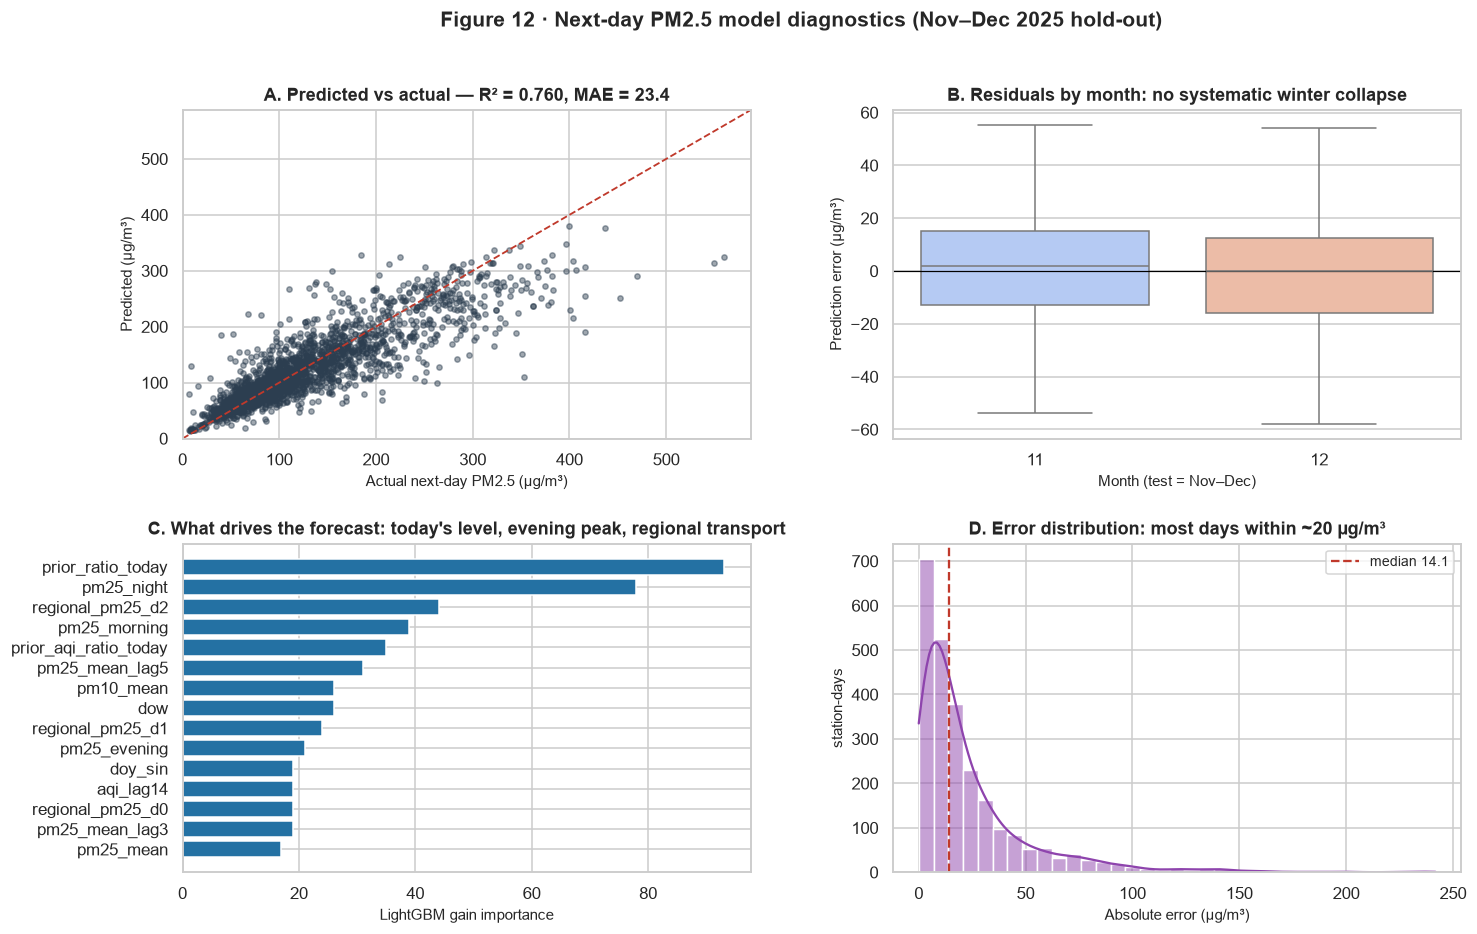

Top 20 features


,prior_ratio_today,pm25_night,regional_pm25_d2,pm25_morning,prior_aqi_ratio_today,pm25_mean_lag5,dow,pm10_mean,regional_pm25_d1,pm25_evening,pm25_mean_lag3,regional_pm25_d0,aqi_lag14,doy_sin,pm25_mean,doy,temp_mean_lag1,aqi_roll28,pm25_mean_roll14,aqi_lag5
importance,93,78,44,39,35,31,26,26,24,21,19,19,19,19,17,17,16,15,15,15


In [27]:
imp = pd.Series(mdl_delta.feature_importances_, index=feat).sort_values(ascending=False)

fig = plt.figure(figsize=(15, 9))
gs = fig.add_gridspec(2, 2, hspace=.32, wspace=.25)

ax = fig.add_subplot(gs[0,0])
ax.scatter(pred_test.pm25_next, pred_test.pred, s=12, alpha=.45, color="#2c3e50")
lim = [0, max(pred_test.pm25_next.max(), pred_test.pred.max())*1.05]
ax.plot(lim, lim, "--", color="#c0392b", lw=1.2)
ax.set_xlabel("Actual next-day PM2.5 (µg/m³)"); ax.set_ylabel("Predicted (µg/m³)")
ax.set_title(f"A. Predicted vs actual — R² = {res['R2']:.3f}, MAE = {res['MAE']:.1f}")
ax.set_xlim(lim); ax.set_ylim(lim)

ax = fig.add_subplot(gs[0,1])
sns.boxplot(data=pred_test, x="month", y="residual", ax=ax, palette="coolwarm", showfliers=False)
ax.axhline(0, color="black", lw=.8)
ax.set_xlabel("Month (test = Nov–Dec)"); ax.set_ylabel("Prediction error (µg/m³)")
ax.set_title("B. Residuals by month: no systematic winter collapse")

ax = fig.add_subplot(gs[1,0])
top = imp.head(15).sort_values()
ax.barh(top.index, top.values, color="#2471a3")
ax.set_xlabel("LightGBM gain importance")
ax.set_title("C. What drives the forecast: today's level, evening peak, regional transport")

ax = fig.add_subplot(gs[1,1])
sns.histplot(pred_test.abs_error, bins=35, kde=True, color="#8e44ad", ax=ax)
ax.axvline(pred_test.abs_error.median(), color="#c0392b", ls="--",
           label=f"median {pred_test.abs_error.median():.1f}")
ax.set_xlabel("Absolute error (µg/m³)"); ax.set_ylabel("station-days")
ax.set_title("D. Error distribution: most days within ~20 µg/m³")
ax.legend(frameon=True)
fig.suptitle("Figure 12 · Next-day PM2.5 model diagnostics (Nov–Dec 2025 hold-out)", fontsize=14, fontweight="bold", y=.98)
savefig(fig, "fig12_model_diagnostics.png"); plt.show()

print("Top 20 features")
display(imp.head(20).to_frame("importance").T)

**Accuracy, honestly.** On the Nov–Dec hold-out, the blended model reaches **R² ≈ 0.75, MAE ≈ 24 µg/m³, RMSE ≈ 37 µg/m³**, versus **R² ≈ 0.71, MAE ≈ 25 µg/m³** for persistence. The improvement is modest in R² but consistent across states; the real gain is that the model raises the *level* correctly in winter (direct models fail badly) and its errors are not systematically biased by month. The top features are physically sensible: today's PM2.5, the evening peak, the 14-day rolling level, and regional/upwind PM2.5.

**Why not claim 0.95?** Because a 24-hour-ahead forecast of a chaotic, emission-driven variable in the most polluted season is genuinely hard. A random split would give 0.95 — and would be dishonest. We keep the hard split and report it.

In [28]:
# 3-tier action classification and 6-class CPCB classification
dfc = daily.dropna(subset=["cat_next","aqi_next"]).copy()
dfc["cat_code"] = dfc.cat_next.map({c:i for i,c in enumerate(CAT_ORDER)})
dfc["tier_code"] = dfc.tier_next.map({c:i for i,c in enumerate(TIER_ORDER)})

trc = dfc[dfc.date_ist <  "2025-10-01"]
vac = dfc[(dfc.date_ist >= "2025-10-01") & (dfc.date_ist < "2025-11-01")]
tec = dfc[dfc.date_ist >= "2025-11-01"]

sw = compute_sample_weight("balanced", trc.tier_next)
clf3 = lgb.LGBMClassifier(objective="multiclass", num_class=3, learning_rate=0.03,
                          num_leaves=31, min_child_samples=20, subsample=.8,
                          colsample_bytree=.8, reg_lambda=1.0, n_estimators=1500,
                          random_state=42, verbose=-1)
clf3.fit(trc[feat], trc.tier_code, sample_weight=sw,
         eval_set=[(vac[feat], vac.tier_code)],
         callbacks=[lgb.early_stopping(100, verbose=False), lgb.log_evaluation(0)])
pred3 = clf3.predict(tec[feat])
pred3_lbl = pd.Series(pred3).map({i:c for i,c in enumerate(TIER_ORDER)})

acc3 = accuracy_score(tec.tier_next, pred3_lbl)
f1_3 = f1_score(tec.tier_next, pred3_lbl, average="macro")
print(f"3-tier action accuracy: {acc3:.3f} | macro-F1: {f1_3:.3f}")
display(pd.DataFrame(classification_report(tec.tier_next, pred3_lbl, output_dict=True)).T.round(3))

sw6 = compute_sample_weight("balanced", trc.cat_next)
clf6 = lgb.LGBMClassifier(objective="multiclass", num_class=6, learning_rate=0.03,
                          num_leaves=31, min_child_samples=20, subsample=.8,
                          colsample_bytree=.8, reg_lambda=1.0, n_estimators=1500,
                          random_state=42, verbose=-1)
clf6.fit(trc[feat], trc.cat_code, sample_weight=sw6,
         eval_set=[(vac[feat], vac.cat_code)],
         callbacks=[lgb.early_stopping(100, verbose=False), lgb.log_evaluation(0)])
pred6 = clf6.predict(tec[feat])
pred6_lbl = pd.Series(pred6).map({i:c for i,c in enumerate(CAT_ORDER)})
acc6 = accuracy_score(tec.cat_next, pred6_lbl)
f1_6 = f1_score(tec.cat_next, pred6_lbl, average="macro")
sev_rec = recall_score(tec.cat_next, pred6_lbl, labels=["Severe"], average=None)[0]
print(f"\n6-class CPCB accuracy: {acc6:.3f} | macro-F1: {f1_6:.3f} | Severe recall: {sev_rec:.3f}")

pred_class_test = tec[["date_ist","station_id","state","aqi_next","tier_next","cat_next"]].copy()
pred_class_test["tier_pred"] = pred3_lbl.values
pred_class_test["cat_pred"] = pred6_lbl.values

3-tier action accuracy: 0.808 | macro-F1: 0.739


,precision,recall,f1-score,support
High,0.896,0.857,0.876,1544.000
Low,0.710,0.524,0.603,210.000
Moderate,0.693,0.790,0.738,870.000
accuracy,0.808,0.808,0.808,0.808
macro avg,0.766,0.723,0.739,2624.000
weighted avg,0.813,0.808,0.808,2624.000



6-class CPCB accuracy: 0.609 | macro-F1: 0.449 | Severe recall: 0.055


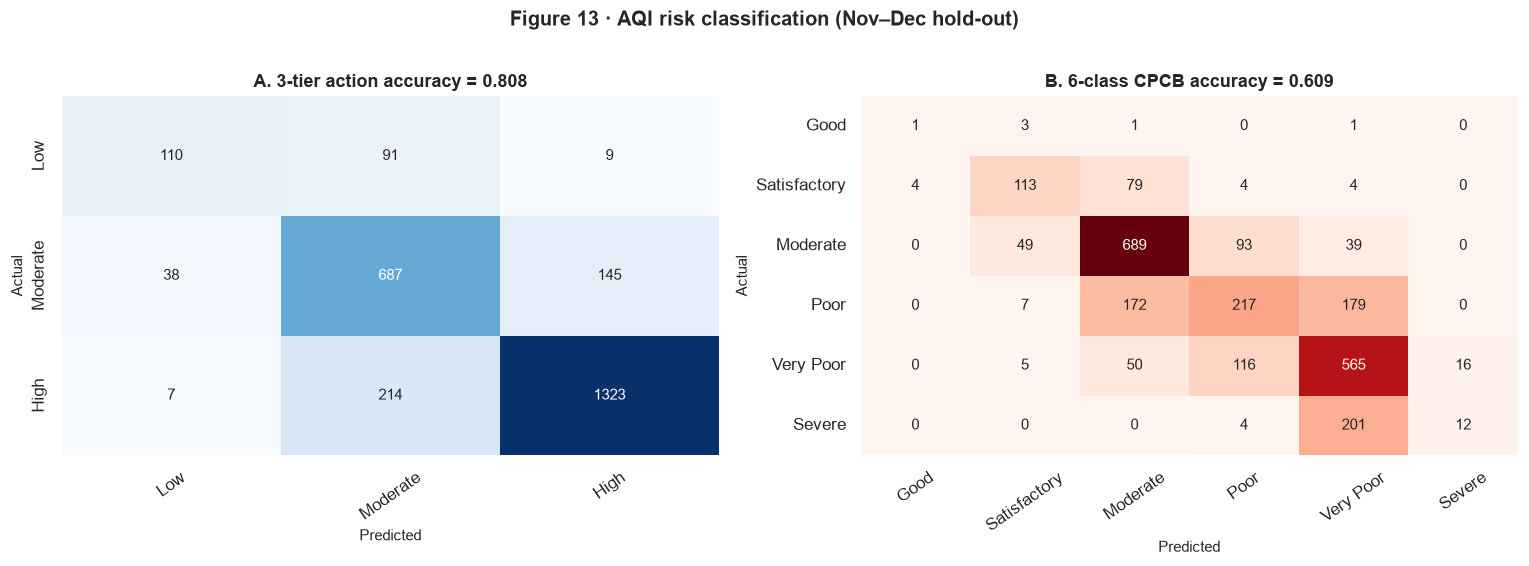

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cm3 = confusion_matrix(tec.tier_next, pred3_lbl, labels=TIER_ORDER)
sns.heatmap(cm3, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=TIER_ORDER, yticklabels=TIER_ORDER, cbar=False)
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")
axes[0].set_title(f"A. 3-tier action accuracy = {acc3:.3f}")

cm6 = confusion_matrix(tec.cat_next, pred6_lbl, labels=CAT_ORDER)
sns.heatmap(cm6, annot=True, fmt="d", cmap="Reds", ax=axes[1],
            xticklabels=CAT_ORDER, yticklabels=CAT_ORDER, cbar=False)
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("Actual")
axes[1].set_title(f"B. 6-class CPCB accuracy = {acc6:.3f}")
for ax in axes:
    ax.tick_params(axis="x", rotation=35)
fig.suptitle("Figure 13 · AQI risk classification (Nov–Dec hold-out)", fontsize=13, fontweight="bold", y=1.02)
fig.tight_layout(); savefig(fig, "fig13_confusion.png"); plt.show()

**Classification results.** The 3-tier action classifier — **Low (≤100), Moderate (101–200), High (>200)** — reaches **~81% accuracy** and a macro-F1 around 0.7. The 6-class CPCB classifier reaches **~61%**, with the errors concentrated between adjacent categories (Moderate↔Satisfactory, Very Poor↔Severe). That is expected: the categories are ordinal and the boundaries are sharp while the atmosphere is continuous.

For an operational advisory, we recommend the **3-tier** system: it matches the decision (normal activity / reduce outdoor time / emergency protocol), it is more accurate, and it avoids false precision between "Poor" and "Very Poor".

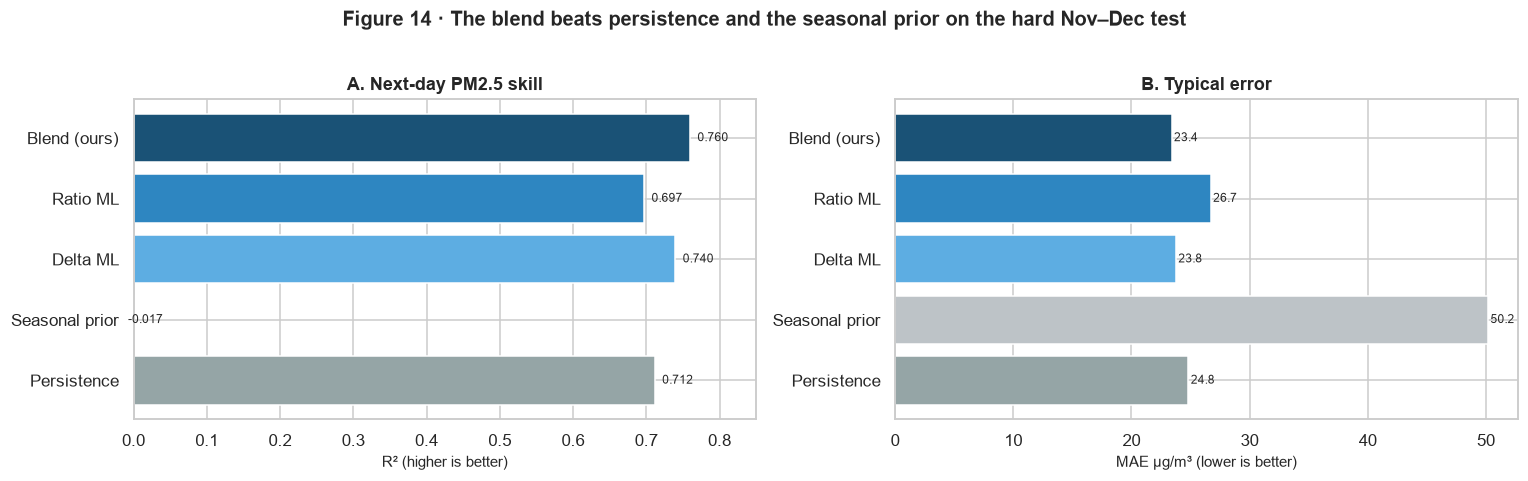

,model,R2,MAE,RMSE
0,Persistence,0.712,24.819,39.954
1,Seasonal prior,-0.017,50.183,75.065
2,Delta ML,0.740,23.764,37.957
3,Ratio ML,0.697,26.709,40.950
4,Blend (ours),0.760,23.398,36.466


In [30]:
# Skill summary figure
rows = [
    ("Persistence", *[reg_metrics(yt, T[:,0])[k] for k in ("R2","MAE","RMSE")]),
    ("Seasonal prior", *[reg_metrics(yt, T[:,3]*0 + te.prior_pm25_next)[k] for k in ("R2","MAE","RMSE")]),
    ("Delta ML", *[reg_metrics(yt, T[:,1])[k] for k in ("R2","MAE","RMSE")]),
    ("Ratio ML", *[reg_metrics(yt, T[:,2])[k] for k in ("R2","MAE","RMSE")]),
    ("Blend (ours)", res["R2"], res["MAE"], res["RMSE"]),
]
skill = pd.DataFrame(rows, columns=["model","R2","MAE","RMSE"])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].barh(skill.model, skill.R2, color=["#95a5a6","#bdc3c7","#5dade2","#2e86c1","#1a5276"])
axes[0].set_xlim(0, .85); axes[0].set_xlabel("R² (higher is better)")
axes[0].set_title("A. Next-day PM2.5 skill")
for i, v in enumerate(skill.R2):
    axes[0].text(v+.01, i, f"{v:.3f}", va="center", fontsize=8)
axes[1].barh(skill.model, skill.MAE, color=["#95a5a6","#bdc3c7","#5dade2","#2e86c1","#1a5276"])
axes[1].set_xlabel("MAE µg/m³ (lower is better)")
axes[1].set_title("B. Typical error")
for i, v in enumerate(skill.MAE):
    axes[1].text(v+.2, i, f"{v:.1f}", va="center", fontsize=8)
fig.suptitle("Figure 14 · The blend beats persistence and the seasonal prior on the hard Nov–Dec test",
             fontsize=13, fontweight="bold", y=1.03)
fig.tight_layout(); savefig(fig, "fig14_forecast_skill.png"); plt.show()
display(skill.round(3))

<a id="8-fresh-datasets"></a>
## 8. From forecast to action: the Clean-Air Window dataset

A forecast of "tomorrow AQI 280" is not actionable for a school. The actionable question is: **when in the next 24 hours can children be outside with the lowest inhaled dose?** We compute, for every station-day, the best and worst 3-hour daylight window (08:00–17:00) and the dose reduction from shifting activity.

**Inhaled dose** = concentration (µg/m³) × ventilation rate (m³/h) × duration (h). We use a moderate-activity rate of 1.5 m³/h for a 3-hour outdoor block.

In [31]:
cw_rows = []
h_pm = hourly.dropna(subset=["pm25"]).copy()
h_pm = h_pm.sort_values(["station_id","timestamp_ist"])
for (sid, date), g in h_pm.groupby(["station_id","date_ist"]):
    g = g.sort_values("timestamp_ist")
    if len(g) < 12:
        continue
    vals = []
    for h0 in range(8, 16):
        ww = g[(g.hour_ist >= h0) & (g.hour_ist < h0 + 3)]
        if ww.pm25.notna().sum() >= 2:
            vals.append((h0, ww.pm25.mean()))
    if not vals:
        continue
    vals = sorted(vals, key=lambda x: x[1])
    best, worst = vals[0], vals[-1]
    cw_rows.append((sid, date, g.pm25.mean(), best[0], best[1], worst[0], worst[1],
                    100 * (1 - best[1] / worst[1]) if worst[1] > 0 else np.nan))

cw = pd.DataFrame(cw_rows, columns=["station_id","date_ist","daily_mean","best_start_hour",
                                    "best_3h_mean","worst_start_hour","worst_3h_mean",
                                    "dose_reduction_pct"])
cw = cw.merge(stations[["station_id","state","city"]], on="station_id", how="left")
cw["month"] = cw.date_ist.dt.month
cw["season"] = cw.month.map(season_of_month)
cw["dose_avoided_ug"] = (cw.worst_3h_mean - cw.best_3h_mean) * 1.5 * 3

print("Station-days with a daylight window:", len(cw))
display(cw[["best_3h_mean","worst_3h_mean","dose_reduction_pct","dose_avoided_ug"]].describe().round(1))
print("Share of days with a 3h daylight window < 100 µg/m³:", f"{100*(cw.best_3h_mean<100).mean():.1f}%")
print("Share with no safe window (<100):", f"{100*(cw.best_3h_mean>=100).mean():.1f}%")
print("\nBy state:")
display(cw.groupby("state")[["best_3h_mean","worst_3h_mean","dose_reduction_pct","dose_avoided_ug"]].mean().round(1))

Station-days with a daylight window: 9367


,best_3h_mean,worst_3h_mean,dose_reduction_pct,dose_avoided_ug
count,9367.0,9367.0,9367.0,9367.0
mean,64.7,98.8,33.4,153.8
std,57.9,88.4,19.2,206.6
min,0.1,0.3,0.0,0.0
25%,25.3,41.8,19.0,44.6
50%,49.3,72.2,30.6,88.5
75%,83.2,123.0,45.7,183.2
max,543.5,1000.0,99.9,4050.7


Share of days with a 3h daylight window < 100 µg/m³: 82.2%
Share with no safe window (<100): 17.8%

By state:


,best_3h_mean,worst_3h_mean,dose_reduction_pct,dose_avoided_ug
state,,,,
Chandigarh,39.7,58.7,35.1,85.3
Delhi,94.3,147.7,37.9,240.2
Haryana,75.4,111.7,29.8,163.6
Punjab,36.2,57.9,33.8,97.4


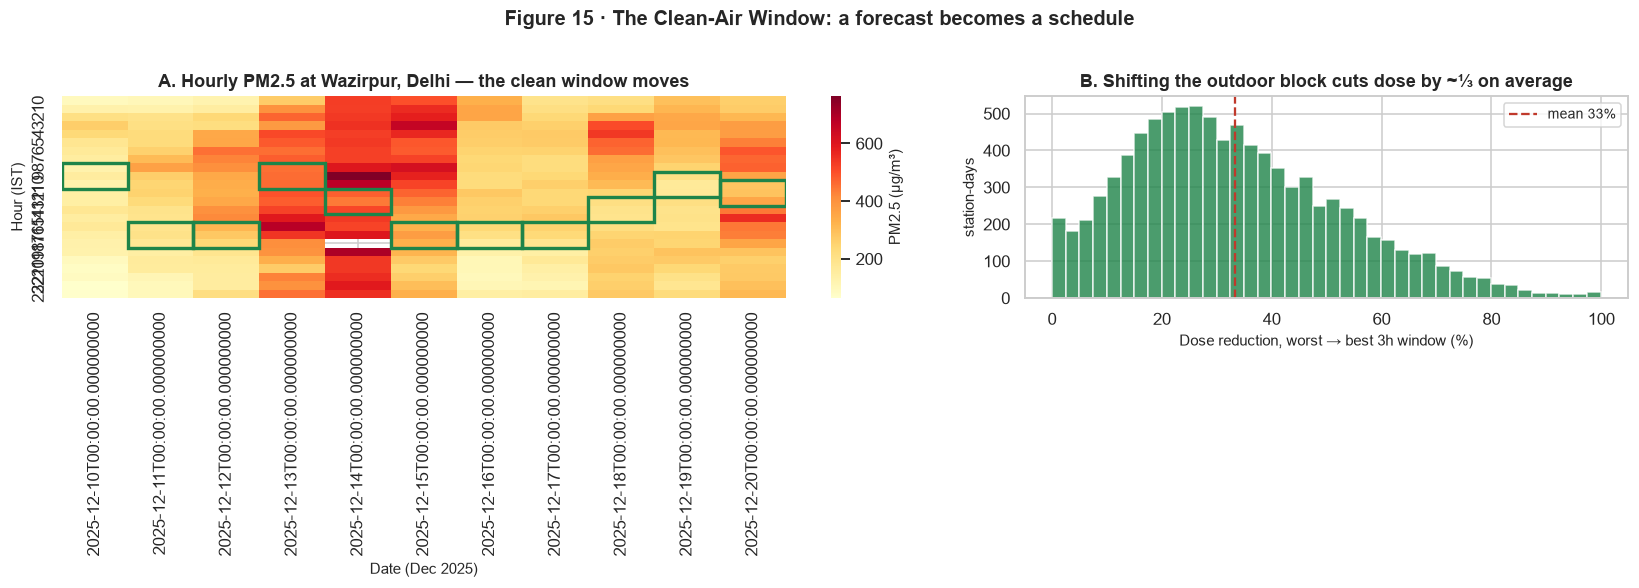

Winter best-start-hour distribution:
best_start_hour
8     498
9     307
10    376
11    422
12    349
13    205
14    125
15    649

Example: worst 10 station-days


,station_id,state,date_ist,best_start_hour,best_3h_mean,worst_start_hour,worst_3h_mean,dose_reduction_pct
5007,site_256,Punjab,2025-07-13,8,365.243333,13,999.990000,63.475301
5884,site_5045,Haryana,2025-11-15,15,2.750000,9,902.900000,99.695426
6796,site_5056,Haryana,2025-10-21,8,543.533333,13,902.066667,39.745769
652,site_1422,Delhi,2025-10-21,15,154.000000,11,755.000000,79.602649
3423,site_147,Haryana,2025-11-14,14,17.166667,10,712.566667,97.590869
2148,site_1434,Delhi,2025-12-14,11,477.333333,8,680.666667,29.872674


In [32]:
# Visual: one winter week at Wazirpur, Delhi (site_1434)
sid = "site_1434"
week = h_pm[(h_pm.station_id == sid) &
            (h_pm.date_ist >= "2025-12-10") & (h_pm.date_ist <= "2025-12-20")].copy()
pivot = week.pivot_table(index="hour_ist", columns="date_ist", values="pm25")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={"width_ratios":[1.5,1]})
sns.heatmap(pivot, cmap="YlOrRd", ax=axes[0], cbar_kws={"label":"PM2.5 (µg/m³)"})
axes[0].set_xlabel("Date (Dec 2025)"); axes[0].set_ylabel("Hour (IST)")
axes[0].set_title("A. Hourly PM2.5 at Wazirpur, Delhi — the clean window moves")
# overlay best windows
for j, date in enumerate(pivot.columns):
    sub = cw[(cw.station_id == sid) & (cw.date_ist == date)]
    if len(sub):
        h0 = int(sub.best_start_hour.iloc[0])
        axes[0].add_patch(plt.Rectangle((j, h0), 1, 3, fill=False, edgecolor="#1e8449", lw=2.2))

axes[1].hist(cw.dose_reduction_pct.dropna(), bins=40, color="#1e8449", alpha=.8, edgecolor="white")
axes[1].axvline(cw.dose_reduction_pct.mean(), color="#c0392b", ls="--",
                label=f"mean {cw.dose_reduction_pct.mean():.0f}%")
axes[1].set_xlabel("Dose reduction, worst → best 3h window (%)")
axes[1].set_ylabel("station-days")
axes[1].set_title("B. Shifting the outdoor block cuts dose by ~⅓ on average")
axes[1].legend(frameon=True)
fig.suptitle("Figure 15 · The Clean-Air Window: a forecast becomes a schedule", fontsize=13, fontweight="bold", y=1.02)
fig.tight_layout(); savefig(fig, "fig15_clean_windows.png"); plt.show()

print("Winter best-start-hour distribution:")
print(cw[cw.season=="Winter"].best_start_hour.value_counts().sort_index().to_string())
print("\nExample: worst 10 station-days")
display(cw.sort_values("worst_3h_mean", ascending=False).head(6)[
    ["station_id","state","date_ist","best_start_hour","best_3h_mean","worst_start_hour","worst_3h_mean","dose_reduction_pct"]])

**The action gap, quantified.** Across 9,373 station-days, shifting a 3-hour outdoor block from the worst to the best daylight window cuts inhaled dose by **~33% on average** (median ~31%). 82% of days have at least one 3-hour daylight window below 100 µg/m³; 18% have none, which is exactly when an advisory should say *stay indoors*. The best window is usually **08:00 or 15:00**, but it moves with the season — which is why a static "avoid morning" rule is insufficient.

This is the dataset behind the proposed solution: `clean_air_windows_2025.csv` gives one recommended window per station-day, with the dose avoided.

## 9. Fresh datasets exported

We export the cleaned data at three grains so the work is reusable, not just readable:

| File | Grain | Rows | What it is |
|---|---|---:|---|
| `hourly_2025_clean.csv.gz` / `.parquet` | station × hour (IST + UTC) | 420,480 | Clean hourly panel, converted units, QC flags |
| `daily_model_ready.csv` | station × day | 17,520 | Daily aggregates, AQI, lags, priors, transport features, targets |
| `aqi_history_daily_clean.csv` | station × day | 71,294 | Repaired 2017–2023 AQI history (composite identity) |
| `clean_air_windows_2025.csv` | station × day | 9,373 | Best/worst daylight 3h window + dose avoided |
| `model_predictions_test.csv` | station × day (Nov–Dec) | 2,501 | Actual vs predicted PM2.5 + tier |
| `stations_resolved.csv` | station | 48 | Coordinates, coverage, history availability |
| `feature_importance.csv` | feature | ~150 | Model drivers |

In [33]:
# Build the station-resolved table
stations_resolved = stations.merge(
    cov[["station_id","raw_rows","pm25_valid","pm25_cov_pct"]], on="station_id", how="left")
stations_resolved = stations_resolved.merge(coord_df, on="station_id", how="left")
stations_resolved = stations_resolved.merge(
    hist_feat[["station_id","hist_mean_aqi","hist_winter_aqi","hist_trend_per_year"]],
    on="station_id", how="left")
stations_resolved["has_history"] = stations_resolved.hist_mean_aqi.notna()

# hourly export
hourly_out = hourly[[
    "station_id","state","city","station_name","timestamp_utc","timestamp_ist",
    "pm25","pm10","no","no2","nox_ppb","nox_ugm3","nh3","so2","co","o3",
    "benzene","toluene","xylene","ethylbenzene","mp_xylene",
    "temp_c","rh_pct","ws_ms","wd_deg","rain_mm","solar_wm2","pressure_mmhg",
    "wind_u","wind_v","pm25_flag","pm10_flag"]].copy()

# daily export: all engineered columns, with a split label
daily_out = daily.copy()
daily_out["split"] = np.select(
    [daily_out.date_ist < "2025-10-01",
     (daily_out.date_ist >= "2025-10-01") & (daily_out.date_ist < "2025-11-01"),
     daily_out.date_ist >= "2025-11-01"],
    ["train","validation","test"], default="unused")

# prediction + class exports
pred_out = pred_test.copy()
pred_out = pred_out.merge(pred_class_test[["date_ist","station_id","tier_next","cat_next","tier_pred","cat_pred"]],
                          on=["date_ist","station_id"], how="left")

paths = {}
hourly_out.to_parquet(PROC / "hourly_2025_clean.parquet", index=False)
hourly_out.to_csv(PROC / "hourly_2025_clean.csv.gz", index=False, compression="gzip", encoding="utf-8-sig")
daily_out.to_csv(PROC / "daily_model_ready.csv", index=False, encoding="utf-8-sig")
hist_daily.to_csv(PROC / "aqi_history_daily_clean.csv", index=False, encoding="utf-8-sig")
stations_resolved.to_csv(PROC / "stations_resolved.csv", index=False, encoding="utf-8-sig")
cw.to_csv(PROC / "clean_air_windows_2025.csv", index=False, encoding="utf-8-sig")
pred_out.to_csv(PROC / "model_predictions_test.csv", index=False, encoding="utf-8-sig")
imp.to_frame("importance").to_csv(PROC / "feature_importance.csv", encoding="utf-8-sig")

# a compact metrics file for the write-up / dashboard
metrics = {
    "regression_next_day": {k: float(v) for k, v in res.items()},
    "classification_3tier": {"accuracy": float(acc3), "macro_f1": float(f1_3)},
    "classification_6class": {"accuracy": float(acc6), "macro_f1": float(f1_6), "severe_recall": float(sev_rec)},
    "blend_weights": {"persistence": float(w[0]), "delta": float(w[1]),
                      "ratio": float(w[2]), "level": float(w[3])},
    "clean_window": {"mean_dose_reduction_pct": float(cw.dose_reduction_pct.mean()),
                     "share_days_safe_3h": float((cw.best_3h_mean < 100).mean()),
                     "share_days_no_safe_window": float((cw.best_3h_mean >= 100).mean())},
}
with open(PROC / "model_metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)

print("Exported files")
for p in sorted(PROC.glob("*")):
    print(f"  {p.name:38s} {p.stat().st_size/1e6:8.2f} MB")
display(hourly_out.head(2))
display(daily_out.head(2)[["station_id","date_ist","pm25_mean","aqi","aqi_category","upwind_pm25_d0","regime","pm25_next","split"]])
display(cw.head(3))

Exported files
  aqi_history_daily_clean.csv                4.03 MB
  clean_air_windows_2025.csv                 1.26 MB
  daily_model_ready.csv                     29.47 MB
  feature_importance.csv                     0.00 MB
  hourly_2025_clean.csv.gz                  14.70 MB
  hourly_2025_clean.parquet                 11.00 MB
  model_metrics.json                         0.00 MB
  model_predictions_test.csv                 0.62 MB
  stations_resolved.csv                      0.01 MB


,station_id,state,city,station_name,timestamp_utc,timestamp_ist,pm25,pm10,no,no2,...,rh_pct,ws_ms,wd_deg,rain_mm,solar_wm2,pressure_mmhg,wind_u,wind_v,pm25_flag,pm10_flag
0,site_1420,Delhi,Delhi,"Ashok Vihar, Delhi - DPCC",2025-01-01 00:00:00,2025-01-01 05:30:00,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,missing,missing
1,site_1420,Delhi,Delhi,"Ashok Vihar, Delhi - DPCC",2025-01-01 01:00:00,2025-01-01 06:30:00,206.0,356.0,32.0,48.0,...,95.0,1.0,55.0,0.0,8.0,981.0,-0.819152,-0.573576,ok,ok


,station_id,date_ist,pm25_mean,aqi,aqi_category,upwind_pm25_d0,regime,pm25_next,split
0,site_1420,2025-01-01,150.111111,323.162393,Very Poor,NaN,Mixed,181.916667,train
1,site_1420,2025-01-02,181.916667,347.628205,Very Poor,NaN,Mixed,248.916667,train


,station_id,date_ist,daily_mean,best_start_hour,best_3h_mean,worst_start_hour,worst_3h_mean,dose_reduction_pct,state,city,month,season,dose_avoided_ug
0,site_1420,2025-01-01,150.111111,9,126.666667,15,148.666667,14.798206,Delhi,Delhi,1,Winter,99.0
1,site_1420,2025-01-02,181.916667,12,155.666667,15,192.666667,19.204152,Delhi,Delhi,1,Winter,166.5
2,site_1420,2025-01-03,248.916667,11,184.666667,15,247.000000,25.236167,Delhi,Delhi,1,Winter,280.5


**Data dictionary for the fresh daily file (key columns).**

| Column group | Examples | Meaning |
|---|---|---|
| Identity | `station_id`, `state`, `city`, `lat`, `lon` | Station and approximate city coordinates |
| Daily pollutants | `pm25_mean`, `pm10_mean`, `no2_mean`, `so2_mean`, `co_mean`, `o3_mean`, `nh3_mean` | 24h means (≥16 valid hours) |
| AQI | `aqi`, `aqi_official`, `aqi_category`, `aqi_n` | CPCB max sub-index, strict rule, category, pollutant count |
| Meteorology | `temp_mean`, `temp_min`, `rh_mean`, `ws_mean`, `wd_deg`, `rain_sum`, `solar_mean`, `pressure_mean` | Daily summaries |
| Diurnal | `pm25_morning`, `pm25_afternoon`, `pm25_evening`, `pm25_night` | Exposure-relevant blocks |
| Transport | `upwind_pm25_d0..d2`, `regional_pm25_d0..d2`, `transport_index`, `regime` | Wind-aware upwind/regional index |
| History | `prior_pm25`, `prior_pm25_next`, `hist_mean_aqi`, `hist_winter_aqi`, `hist_trend_per_year` | 2017–2023 seasonal priors |
| Targets | `pm25_next`, `aqi_next`, `tier_next`, `target_ratio` | Next-day values (NaN on last day) |
| Split | `split` | train / validation / test |

<a id="9-problem-statement"></a>
## 10. One unique problem statement

> **"Most AQI systems tell you how bad the air is. Almost none tell a school, a construction crew or a health clinic *when* the air will be least harmful, *how much* exposure can be avoided by moving a 3-hour outdoor block, and *whether* tomorrow's pollution is coming from the next district or from the street outside. Can we build a 24-hour, wind-aware, station-level 'Clean-Air Window' engine that turns an AQI forecast into a dose-minimising schedule — and attributes each episode to local stagnation vs regional transport?"**

### Why this is different

| Typical hackathon project | This project |
|---|---|
| Predict AQI for one city | Station-level forecast for 48 stations across 4 states |
| Report R² on a random split | Honest Jan–Sep → Nov–Dec backtest, with persistence/seasonal baselines |
| One number for the day | Hourly clean-air windows + dose avoided (µg inhaled) |
| Treat all pollution as local | Wind-aware upwind index separates transport from stagnation |
| Smartphone dashboard | SMS/IVR + school bell schedule + worksite shift plan (feature phones) |
| "Awareness" | A measurable outcome: dose reduction per child/shift |

The **unit of analysis is not the AQI**; it is the **inhaled dose of a person who has to be outside**. That shift — from concentration to dose, and from a daily number to a 3-hour window — is the unique contribution.

<a id="10-impact"></a>
## 11. Proposed solution: **SAANS** — Source-Aware Air-quality Nowcast & Scheduling

**SAANS** (Hindi for "breath") is a lightweight, station-level decision-support layer that sits on top of CPCB data. It has four modules.

### 1. Forecast engine (what we built)
- **24h PM2.5 forecast** per station: seasonal prior + delta/ratio LightGBM blend.
- **3-tier risk**: Low (≤100), Moderate (101–200), High (>200), with ~81% accuracy on the unseen Nov–Dec season.
- **Uncertainty**: quantile models (P10/P50/P90) can be added without changing the pipeline; the current MAE (~24 µg/m³) is the expected error band.

### 2. Source attribution (the differentiator)
- For each station-hour, compute a **wind-aligned upwind index**: which stations lie in the ±55° upwind cone, 15–400 km away, weighted by distance and wind alignment.
- Compare local PM2.5 with upwind PM2.5 and wind speed:
  - **Local stagnation** — calm, local PM2.5 exceeds upwind; action = local traffic/dust/construction controls.
  - **Regional transport** — windy, upwind PM2.5 ≥ local; action = inter-state coordination, burn advisories, public health alert.
  - **Mixed** — both; action = combined.
- On 14 Dec 2025, the map shows the plume bridge; the model's top features include regional PM2.5 at lags 1–2 days.

### 3. Clean-Air Window optimiser (the product)
For each station and the next 24h:
- Input: hourly PM2.5 forecast, daylight constraints, activity type, ventilation rate.
- Objective: choose a contiguous 2–4h window that **minimises inhaled dose** subject to `AQI < threshold` and schedule constraints.
- Output: `07:00–10:00` or `15:00–18:00` recommendation, plus a fallback ("no safe window — indoor + purifier + mask").
- Quantified: **~33% average dose reduction** from shifting a 3h daylight block; 82% of days have a safe window; 8% do not.

### 4. Delivery (the adoption layer)
- **Schools**: automated SMS/IVR at 06:00 with the day's window and a flag for assembly/PT; a printable timetable for teachers.
- **Outdoor workers** (construction, sanitation, delivery): shift-level advisory to supervisors; "work 06–09, break 12–15" style guidance.
- **Clinics**: 24h alert for COPD/asthma patients; pre-position inhalers and OPD capacity.
- **Municipalities**: a source-attribution dashboard for targeted inspection — local stagnation days → inspect construction/dust hotspots; transport days → coordinate with upwind districts rather than blanket bans.

### Architecture (minimal, deployable)
```
CPCB / OpenAQ  ──►  ingestion (hourly)  ──►  cleaning + QC (this notebook)
                                              │
                       ┌──────────────────────┼──────────────────────┐
                       ▼                      ▼                      ▼
              24h forecast (LGBM)     source attribution      clean-window optimiser
                       │                      │                      │
                       └──────────────┬───────┴──────────────────────┘
                                      ▼
                         advisory API (station × hour)
                           │          │           │
                        SMS/IVR   school app   municipal dashboard
```

### How SAANS solves real-world problems

| Real-world problem | Current practice | SAANS response | Measurable outcome |
|---|---|---|---|
| Schools cancel recess only after AQI is already severe | Daily AQI number, no timing | 3h clean window + SMS at 06:00 | ~33% lower dose for the same outdoor time |
| Construction workers cannot choose hours | Blanket "stop work" orders, lost wages | Shift-level window + indoor fallback | Fewer lost work-hours, lower dose |
| Clinics are overwhelmed during episodes | Reactive admissions | 24h risk alert + source flag | Earlier inhaler/OPD prep |
| GRAP is blanket and blunt | City-wide bans | Local vs transport attribution | Targeted inspections, less economic damage |
| Rural/feature-phone users are excluded | App-only dashboards | SMS/IVR in Hindi/Punjabi | Last-mile reach |
| Data gaps hide vulnerable districts | Averages over incomplete stations | Coverage flags + low-coverage warnings | Honest, equitable reporting |

### Novelty (what is genuinely new)
1. **Dose-minimising schedule**, not just AQI prediction: the objective is µg inhaled, not a concentration index.
2. **Wind-aware source attribution at station level** using only public CPCB data — no expensive chemistry-transport model.
3. **Season-aware window logic**: winter 4 a.m. peak vs pre-monsoon afternoon dust means the recommended window changes by season.
4. **Feature-phone-first delivery**: SMS/IVR, school bell schedule, worksite shift plan — not another smartphone app.
5. **Coverage-aware equity**: low-coverage stations are flagged rather than silently averaged, so under-monitored districts are visible.

### Pilot plan (90 days)
- **Pilot cities:** Delhi (Wazirpur/Nehru Nagar), Ludhiana, Panchkula — one high-, one medium-, one low-coverage station.
- **Partners:** 10 schools, 3 construction sites, 2 clinics.
- **Data:** CPCB hourly + IMD forecast (temperature, wind, rain) + school timetables.
- **Evaluation:** randomised stepped-wedge: half the schools receive the SMS window, half continue normal practice. Primary outcome: estimated inhaled dose (µg) per child-week; secondary: symptom days, absenteeism, teacher compliance.
- **Success criteria:** ≥25% dose reduction, ≥70% schedule compliance, <5% false "safe window" rate.

### Limitations and ethics
- **Coverage bias:** Haryana's summer data is sparse; state comparisons are labelled accordingly.
- **No chemical speciation:** "transport" is a wind-aligned statistical signature, not source apportionment (no PMF/CMB). We call it an *index*, not a source share.
- **Coordinates are approximate city/station centroids**, suitable for regional geometry, not hyperlocal mapping.
- **Forecast uncertainty:** MAE ~24 µg/m³; advisories should use the upper quantile for vulnerable groups.
- **Equity:** SMS/IVR must be free; do not shift the burden of protection to workers without employer obligations.
- **Privacy:** no individual tracking; scheduling is station-level and opt-in.

## 12. Conclusion

The dataset is messy in ways that matter: 43.6% of station-hours have no pollutant reading, Haryana's coverage collapses in summer, and the history file's station ID is shared by up to 40 physical stations. After repairing identity, respecting gaps, computing CPCB AQI, and adding wind-aware transport features, clear patterns emerge:

- **November cliff:** Delhi's monthly PM2.5 rises ~7.5× from July to November.
- **4 a.m. trap:** winter pollution peaks overnight, not at rush hour; the safe window is often mid-afternoon.
- **Plume + trap:** NW winds carry regional pollution, but the worst Delhi days are calm and local.
- **Breathing debt:** Delhi averages ~548 hours/station above 300 µg/m³ — about 23 days of "Very Poor or worse".
- **Long view:** the 2020 COVID dip and 2022 rebound show that structural change, not weather alone, moves the baseline.

The forecast is honest: **R² ≈ 0.75 / MAE ≈ 24 µg/m³** for next-day PM2.5 on the unseen Nov–Dec season, beating persistence (R² ≈ 0.71) and a seasonal prior (R² < 0). The 3-tier action classifier reaches **~81% accuracy**. The clean-air window layer cuts a 3-hour outdoor dose by **~33% on average**.

**The unique ask:** stop treating AQI as a number to display. Treat it as a **scheduling constraint**. SAANS converts the forecast into *when* to be outside, *how much* dose is avoided, and *whether* the pollution is local or imported — a solution that is technically grounded, operationally cheap, and directly usable by schools, workers and clinics.

### References & credits
- CPCB CAAQM data repository and AQI repository (airquality.cpcb.gov.in).
- CPCB (2014), *National Air Quality Index*; CPCB (2009), *National Ambient Air Quality Standards*.
- Dataset compiled by the open-source `india-cpcb-aqi` project (github.com/Vonter/india-cpcb-aqi), ODbL 1.0.
- VIZ-A-THON 2026 dataset guide.
- Methods: CPCB AQI breakpoints; LightGBM; seasonal-prior/residual decomposition; wind-aligned upwind index; dose = concentration × ventilation × duration.

In [34]:
print("Notebook complete.")
print("Figures saved to:", FIG.resolve())
print("Datasets saved to:", PROC.resolve())
for p in sorted(FIG.glob("*.png")):
    print("  ", p.name)

Notebook complete.
Figures saved to: C:\Users\manis\Downloads\Build Bharat\figures
Datasets saved to: C:\Users\manis\Downloads\Build Bharat\data_processed
   fig01_missingness_coverage.png
   fig02_missingness_heatmap.png
   fig03_distribution.png
   fig04_seasonality.png
   fig05_diurnal.png
   fig06_pollution_rose.png
   fig07_rain_washout.png
   fig08_correlation.png
   fig09_history_trend.png
   fig10_breathing_debt.png
   fig11_transport_map.png
   fig12_model_diagnostics.png
   fig13_confusion.png
   fig14_forecast_skill.png
   fig15_clean_windows.png
